# PS-31 · Waste Segregation at Source
## Multiclass waste-material classification with Convolutional Neural Networks (TrashNet)

**Name:** Karthik.K.S  |  **Register No.:** RA2311026050027  |  **Section:** AIML-A  |  **PS-31**  |  **GitHub:** https://github.com/KS-KARTHIK-05/CBL

**Domain:** Environment & Remote Sensing  **Dataset:** [TrashNet](https://github.com/garythung/trashnet) (Thung & Yang, 2016), 2,527 RGB images, 6 classes

**How to run:** select a Python 3 kernel and *Run All*. The first cell installs the libraries; the dataset (43 MB) and the ImageNet weights are downloaded automatically. If a local copy of the dataset is provided, place the `dataset-resized` folder inside `data/` and the download is skipped. Full run: about 30 min on an RTX 4050 laptop GPU.

Smart bins and material-recovery facilities (MRFs) need to sort dry waste automatically. The task is to classify a photo of a **single waste item** into one of six material classes: **glass, paper, cardboard, plastic, metal, trash**.

The `trash` class has only 137 images, about a quarter of the size of `paper`, so a model can score high overall accuracy while doing poorly on it. This notebook therefore:

* reports **per-class** precision, recall and F1, and uses **macro-averaged** metrics (every class counts equally) for model selection;
* handles the imbalance with a **class-weighted loss** and measures its effect in an ablation;
* finishes with an **error analysis of the trash class**: which classes it is confused with, failure examples, confidence, feature-space (t-SNE) and Grad-CAM views.

| Section | Content |
|---|---|
| 1 | Setup: install libraries, seeds, GPU, plot style |
| 2 | Dataset: download, audit (class balance, image sizes, duplicate and label-conflict check) |
| 3 | Leakage-safe stratified train / validation / test split (70 / 15 / 15) |
| 4 | Data pipeline: augmentation and class-weighted loss |
| 5 | Training and evaluation engine |
| 6 | **Model A**: custom CNN (*WasteNet*) trained from scratch |
| 7 | **Model B**: ResNet-50 (ImageNet pre-trained), fine-tuned |
| 8 | **Model C**: EfficientNet-B0 (ImageNet pre-trained), fine-tuned |
| 9 | Ablation: class-weighted vs. unweighted loss |
| 10 | Test-set evaluation: overall metrics with bootstrap CIs, per-class report, confusion matrices, PR curves |
| 11 | Trash-class error analysis |
| 12 | Deployment view: model size, latency, single-image inference |
| 13 | Conclusions |

## 1. Setup
### 1.1 Install libraries
`%pip` is the notebook form of `!pip`: it installs into the Python environment of the running kernel. The PyPI wheels of PyTorch for Linux/Windows include CUDA support.

In [1]:
%pip install -q torch torchvision numpy pandas matplotlib scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, copy, json, time, random, hashlib, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support, precision_recall_curve,
                             average_precision_score, roc_auc_score, top_k_accuracy_score)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Python {sys.version.split()[0]} | torch {torch.__version__} | torchvision {torchvision.__version__} '
      f'| scikit-learn {sklearn.__version__} | numpy {np.__version__}')
print('Device:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU (training will be slow)')

Python 3.14.4 | torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | scikit-learn 1.9.1 | numpy 2.5.4
Device: NVIDIA GeForce RTX 4050 Laptop GPU


### 1.2 Configuration and reproducibility

In [3]:
SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
CLASSES = ['glass', 'paper', 'cardboard', 'plastic', 'metal', 'trash']   # fixed order used everywhere
NUM_CLASSES = len(CLASSES)
TRASH = CLASSES.index('trash')

DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR = Path('data'), Path('figures'), Path('models'), Path('results')
for d in (DATA_DIR, FIG_DIR, MODEL_DIR, RESULTS_DIR):
    d.mkdir(exist_ok=True)

# Parallel data loading. Datasets defined inside a notebook need the 'fork' start method (Linux only)
NUM_WORKERS = min(8, os.cpu_count() or 1) if sys.platform.startswith('linux') else 0
MP_CONTEXT = 'fork' if NUM_WORKERS > 0 else None

# Mixed precision on GPU: bfloat16 where supported, otherwise float16 with gradient scaling
USE_AMP = DEVICE.type == 'cuda'
AMP_DTYPE = torch.bfloat16 if USE_AMP and torch.cuda.is_bf16_supported() else torch.float16

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything()
torch.backends.cudnn.benchmark = False      # deterministic convolution algorithms, so a re-run reproduces the numbers
torch.backends.cudnn.deterministic = True   # (a few GPU kernels use atomic adds, so tiny run-to-run differences can remain)
print(f'seed={SEED}, workers={NUM_WORKERS}, mixed precision={USE_AMP} ({AMP_DTYPE})')

seed=42, workers=8, mixed precision=True (torch.bfloat16)


### 1.3 Plot style
One fixed colour per class across every chart, hairline grids, and a single-hue blue ramp for heatmaps.

In [4]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
CLASS_COLOR = dict(zip(CLASSES, SERIES))
CLASS_MARKER = dict(zip(CLASSES, ['o', 's', '^', 'D', 'v', 'P']))
BLUES = LinearSegmentedColormap.from_list(
    'blues', ['#fcfcfb', '#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
CAM_CMAP = LinearSegmentedColormap.from_list('cam', [(0.92, 0.41, 0.20, 0.0), (0.92, 0.41, 0.20, 0.8)])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'xtick.labelcolor': INK_2, 'ytick.labelcolor': INK_2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'legend.frameon': False, 'legend.fontsize': 9, 'lines.linewidth': 2,
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
})

def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')

def hide_axes(ax):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values():
        s.set_visible(False)

## 2. Dataset
### 2.1 Download TrashNet
The official repository ships `dataset-resized.zip` (43 MB): every photo downscaled to 512 × 384 px. macOS metadata in the archive (`__MACOSX`, `.DS_Store`) is skipped.

In [5]:
ZIP_URL = 'https://raw.githubusercontent.com/garythung/trashnet/master/data/dataset-resized.zip'
zip_path = DATA_DIR / 'dataset-resized.zip'
IMAGE_DIR = DATA_DIR / 'dataset-resized'

if not zip_path.exists():
    print('Downloading TrashNet ...')
    urllib.request.urlretrieve(ZIP_URL, zip_path)
if not IMAGE_DIR.exists():
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_DIR, members=[m for m in zf.namelist()
                                         if m.startswith('dataset-resized/') and m.endswith('.jpg')])
print(f'{zip_path} ({zip_path.stat().st_size / 1e6:.1f} MB) -> {sum(1 for _ in IMAGE_DIR.rglob("*.jpg"))} images')

data/dataset-resized.zip (42.8 MB) -> 2527 images


### 2.2 Class balance and image properties

In [6]:
def image_size(path):
    with Image.open(path) as im:
        return im.size

df = pd.DataFrame([{'path': str(p), 'label': p.parent.name} for p in sorted(IMAGE_DIR.rglob('*.jpg'))])
df['y'] = df['label'].map(CLASSES.index)
print('Total images:', len(df))
print('Image sizes (W x H):', pd.Series([image_size(p) for p in df['path']]).value_counts().to_dict())

counts = df['label'].value_counts().reindex(CLASSES)
display(pd.DataFrame({'images': counts, 'share (%)': (100 * counts / counts.sum()).round(1)}).T)
print(f'Imbalance ratio (largest / smallest class) = {counts.max()} / {counts.min()} = {counts.max() / counts.min():.2f}')

Total images: 2527
Image sizes (W x H): {(512, 384): 2527}


label,glass,paper,cardboard,plastic,metal,trash
images,501.0,594.0,403.0,482.0,410.0,137.0
share (%),19.8,23.5,15.9,19.1,16.2,5.4


Imbalance ratio (largest / smallest class) = 594 / 137 = 4.34


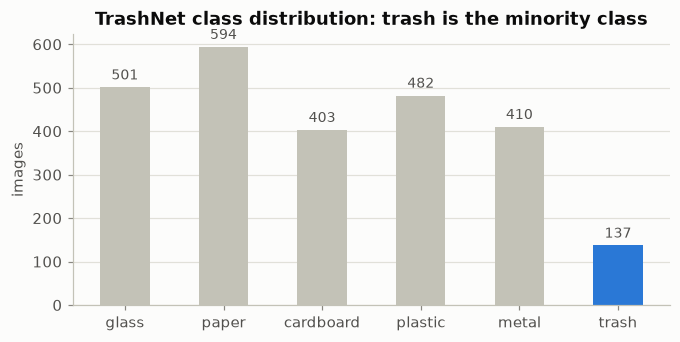

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(CLASSES, counts.values, width=0.5, color=[SERIES[0] if c == 'trash' else AXIS for c in CLASSES])
ax.bar_label(bars, padding=3, color=INK_2, fontsize=9)
ax.set(ylabel='images', title='TrashNet class distribution: trash is the minority class')
ax.grid(axis='x', visible=False)
save(fig, '01_class_distribution'); plt.show()

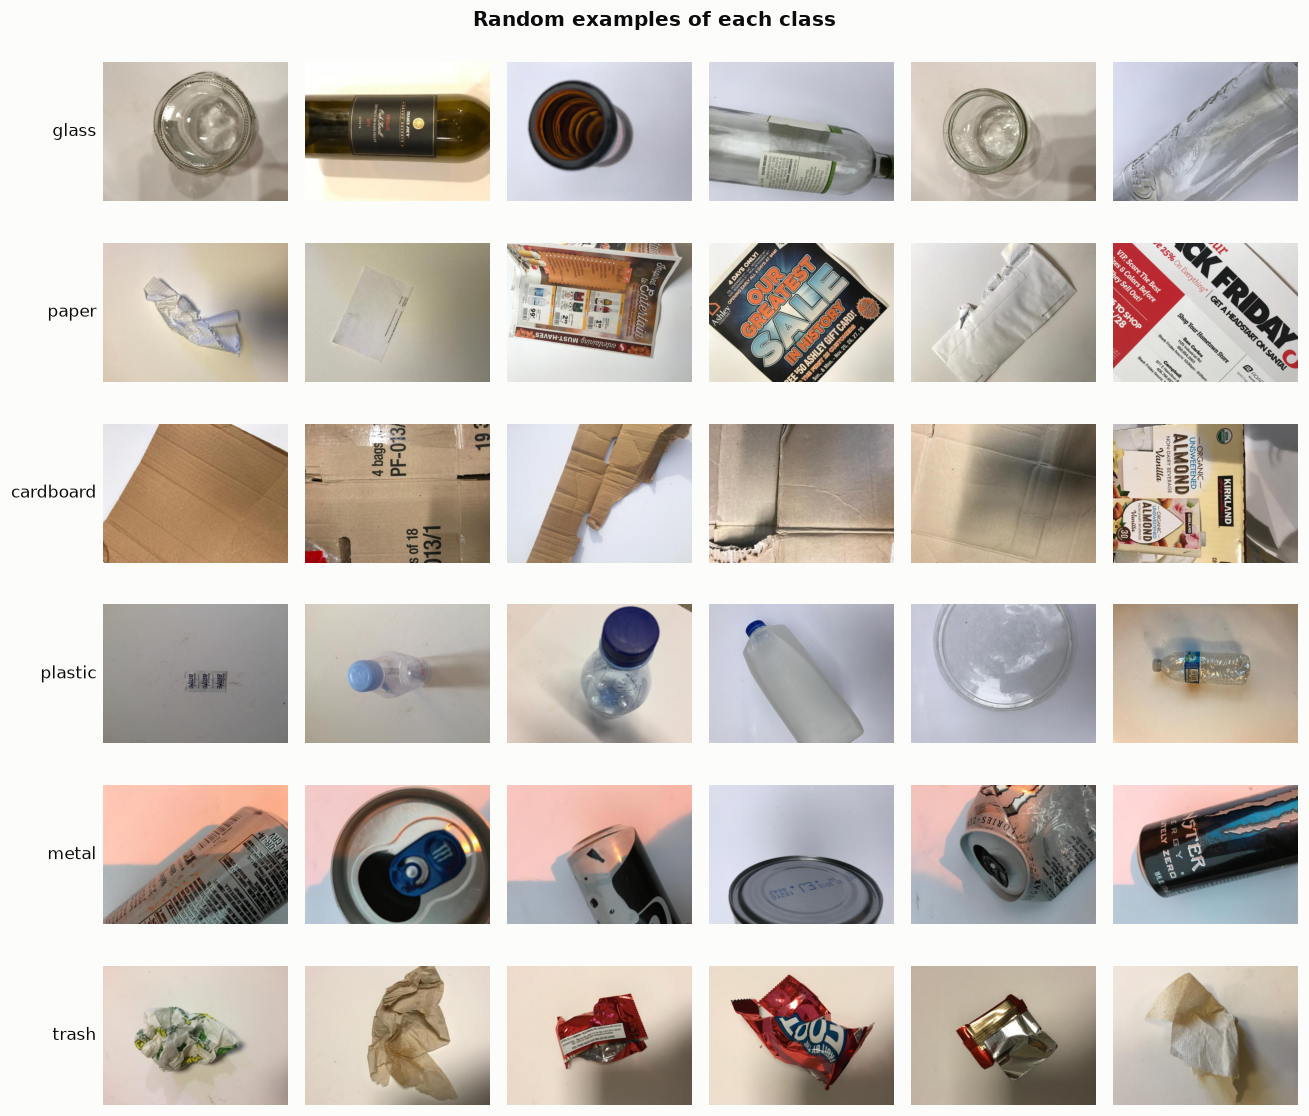

In [8]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(12, 10.5))
for r, c in enumerate(CLASSES):
    for ax, path in zip(axes[r], rng.choice(df.loc[df.label == c, 'path'].values, 6, replace=False)):
        ax.imshow(Image.open(path)); hide_axes(ax)
    axes[r, 0].set_ylabel(c, rotation=0, ha='right', va='center', fontsize=11, color=INK)
fig.suptitle('Random examples of each class', fontsize=13, fontweight='bold')
plt.tight_layout(); save(fig, '02_samples'); plt.show()

### 2.3 Duplicate and label-conflict audit
TrashNet was photographed by hand on a white poster board, so two checks are needed before splitting:

1. **Exact duplicates** (identical MD5 hash). If the *same file* appears under two class folders, its label is contradictory: one of the copies is guaranteed to be "wrong" and it would also leak between train and test. Conflicting copies are removed.
2. **Near-duplicates** (several shots of the same object). Images are compared by the cosine similarity of 32 × 24 colour thumbnails; images linked by a similarity ≥ 0.98 form a *group*, and a whole group is always assigned to the same split. This prevents the test set from containing almost-copies of training images, which would inflate the scores.

Files that are exact duplicates of another file: 6 (3 distinct images)
Of these, duplicates stored under DIFFERENT classes: 3 images


,file,label,md5
421,glass115.jpg,glass,70df08c3ce6d55e25df4edbbe45e5fe3
1305,metal91.jpg,metal,70df08c3ce6d55e25df4edbbe45e5fe3
488,glass176.jpg,glass,a2236bc6f8eae80bf7d6c5f259df8760
1967,plastic152.jpg,plastic,a2236bc6f8eae80bf7d6c5f259df8760
724,glass389.jpg,glass,e52ec9a8f6089b5780728b148c9f795e
2167,plastic332.jpg,plastic,e52ec9a8f6089b5780728b148c9f795e


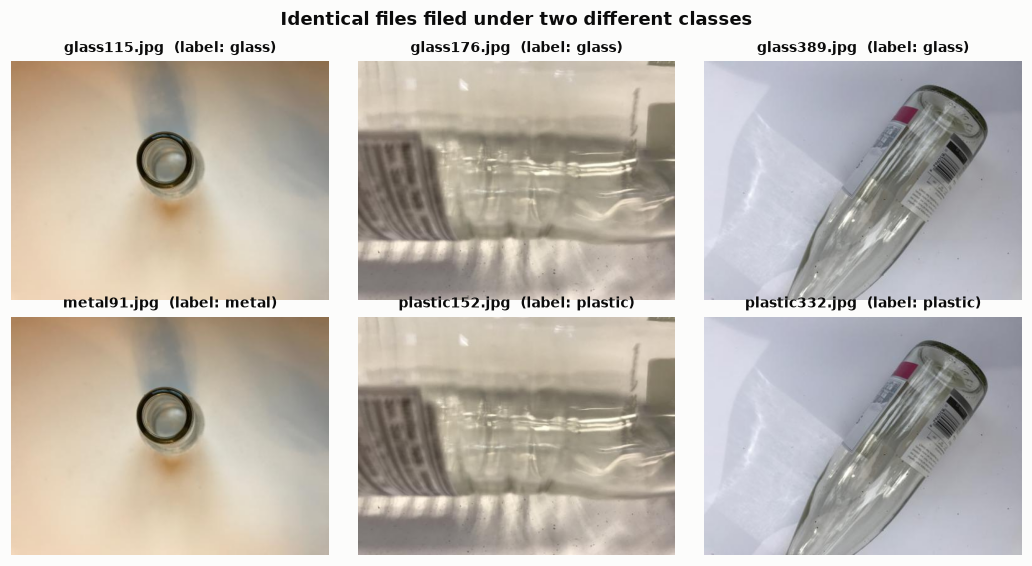

In [9]:
df['md5'] = [hashlib.md5(Path(p).read_bytes()).hexdigest() for p in df['path']]
dups = df[df.duplicated('md5', keep=False)].sort_values(['md5', 'label'])
conflict_md5 = dups.groupby('md5')['label'].nunique().loc[lambda s: s > 1].index
print(f'Files that are exact duplicates of another file: {len(dups)} ({dups.md5.nunique()} distinct images)')
print(f'Of these, duplicates stored under DIFFERENT classes: {len(conflict_md5)} images')
display(dups[dups.md5.isin(conflict_md5)].assign(file=lambda d: d.path.map(lambda p: Path(p).name))[['file', 'label', 'md5']])

pairs = [dups[dups.md5 == h] for h in conflict_md5]
if pairs:
    fig, axes = plt.subplots(2, len(pairs), figsize=(3.2 * len(pairs), 5.2), squeeze=False)
    for col, pair in enumerate(pairs):
        for row, (_, r) in enumerate(pair.iterrows()):
            axes[row, col].imshow(Image.open(r.path)); hide_axes(axes[row, col])
            axes[row, col].set_title(f'{Path(r.path).name}  (label: {r.label})', fontsize=9)
    fig.suptitle('Identical files filed under two different classes', fontsize=12, fontweight='bold')
    plt.tight_layout(); save(fig, '03_label_conflicts'); plt.show()

In [10]:
before = len(df)
df = df[~df.md5.isin(conflict_md5)].drop_duplicates('md5').reset_index(drop=True)
print(f'Removed {before - len(df)} images with contradictory labels / exact duplicates -> {len(df)} images remain')

def thumbnail_vector(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert('RGB').resize((32, 24), Image.BILINEAR), dtype=np.float32).ravel()
    a -= a.mean()
    return a / (np.linalg.norm(a) + 1e-8)

T = np.stack([thumbnail_vector(p) for p in df['path']])
S = T @ T.T                                        # cosine similarity between all image pairs
NEAR_DUP_SIM = 0.98
iu, ju = np.where(np.triu(S >= NEAR_DUP_SIM, k=1))

parent = list(range(len(df)))                      # union-find: linked images share one group id
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for i, j in zip(iu, ju):
    parent[find(i)] = find(j)
df['group'] = [find(i) for i in range(len(df))]

group_sizes = df.groupby('group').size()
print(f'Near-duplicate pairs (cosine >= {NEAR_DUP_SIM}): {len(iu)}')
print(f'Groups with more than one image: {(group_sizes > 1).sum()} (covering {group_sizes[group_sizes > 1].sum()} images)')
print('Every group contains a single class:', bool(df.groupby('group')['label'].nunique().max() == 1))

Removed 6 images with contradictory labels / exact duplicates -> 2521 images remain


Near-duplicate pairs (cosine >= 0.98): 19
Groups with more than one image: 19 (covering 38 images)
Every group contains a single class: True


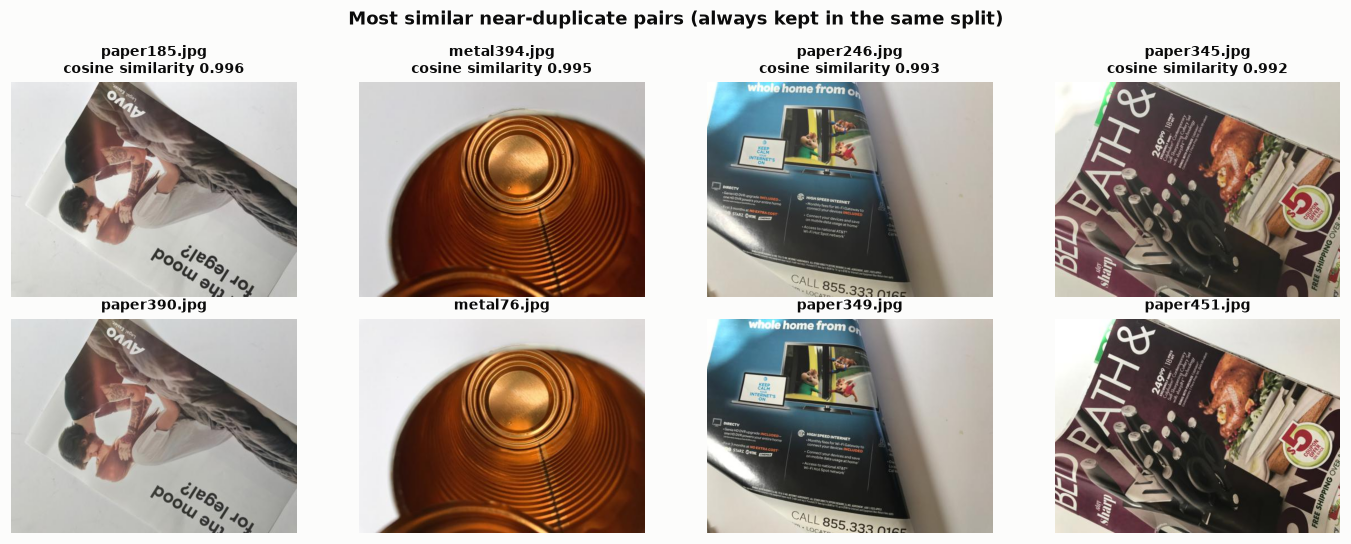

In [11]:
order = np.argsort(-S[iu, ju])[:4]
fig, axes = plt.subplots(2, len(order), figsize=(3.2 * len(order), 5))
for col, k in enumerate(order):
    for row, idx in enumerate((iu[k], ju[k])):
        axes[row, col].imshow(Image.open(df.path[idx])); hide_axes(axes[row, col])
        axes[row, col].set_title(Path(df.path[idx]).name, fontsize=9)
    axes[0, col].set_title(f'{Path(df.path[iu[k]]).name}\ncosine similarity {S[iu[k], ju[k]]:.3f}', fontsize=9)
fig.suptitle('Most similar near-duplicate pairs (always kept in the same split)', fontsize=12, fontweight='bold')
plt.tight_layout(); save(fig, '04_near_duplicates'); plt.show()

**Observations (data audit)**

* All 2,527 images are 512 × 384. Class sizes range from 137 (trash) to 594 (paper), an **imbalance ratio of 4.3 : 1**; trash is only **5.4 %** of the data.
* **Label noise found:** three files exist twice under *different* class folders (metal91 = glass115, plastic152 = glass176, plastic332 = glass389). An identical image cannot belong to two materials, so all 6 copies were removed → **2,521 images used**.
* **19 near-duplicate pairs** (38 images, the same object photographed twice) were found; every pair has a single label. Each pair is kept inside one split, so the test set never contains a near-copy of a training image.
* Every item is photographed alone, centred on a white board under indoor light. The background therefore carries no class information, but the data is also much cleaner than what a real bin camera would see.

## 3. Train / validation / test split
A **stratified** split at the level of near-duplicate *groups*, 70 % train, 15 % validation, 15 % test, with a fixed seed. Stratification keeps the trash share equal in all three splits. The validation set is used for model selection and early stopping; the test set is used **only once**, for the final evaluation.

In [12]:
groups = df.groupby('group')['label'].first().reset_index()
g_train, g_rest = train_test_split(groups, test_size=0.30, stratify=groups['label'], random_state=SEED)
g_val, g_test = train_test_split(g_rest, test_size=0.50, stratify=g_rest['label'], random_state=SEED)
split_of = {**dict.fromkeys(g_train.group, 'train'), **dict.fromkeys(g_val.group, 'val'), **dict.fromkeys(g_test.group, 'test')}
df['split'] = df['group'].map(split_of)
train_df, val_df, test_df = (df[df.split == s].reset_index(drop=True) for s in ('train', 'val', 'test'))

split_table = pd.crosstab(df['label'], df['split']).reindex(index=CLASSES, columns=['train', 'val', 'test'])
split_table.loc['total'] = split_table.sum()
display(split_table)
for name, part in (('train', train_df), ('val', val_df), ('test', test_df)):
    print(f'{name:5s}: {len(part):4d} images, trash share {100 * (part.y == TRASH).mean():.1f} %')
df[['path', 'label', 'split', 'group']].to_csv(RESULTS_DIR / 'split.csv', index=False)

split,train,val,test
label,,,
glass,348,75,75
paper,417,88,89
cardboard,282,60,61
plastic,336,72,72
metal,287,61,61
trash,96,21,20
total,1766,377,378


train: 1766 images, trash share 5.4 %
val  :  377 images, trash share 5.6 %
test :  378 images, trash share 5.3 %


## 4. Data pipeline
### 4.1 Augmentation
Items were photographed in arbitrary orientations and under varying light, so the training images are randomly **rotated (±20°), flipped (both axes), cropped and rescaled (60–100 % of the area), and colour-jittered**. Hue jitter is kept very small because colour is a genuine material cue (brown cardboard, green glass). For validation and test, the whole image is resized to 224 × 224 so the complete object stays visible. Inputs are normalised with ImageNet statistics, which the pre-trained models expect.

In [13]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomRotation(20, fill=255),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.75, 1.333)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class WasteDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths, self.labels, self.transform = frame['path'].tolist(), frame['y'].tolist(), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            img = im.convert('RGB')
        return self.transform(img), self.labels[i]

def make_loader(frame, transform, shuffle):
    return DataLoader(WasteDataset(frame, transform), batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, multiprocessing_context=MP_CONTEXT,
                      persistent_workers=NUM_WORKERS > 0, pin_memory=DEVICE.type == 'cuda',
                      generator=torch.Generator().manual_seed(SEED))

train_loader = make_loader(train_df, train_tf, shuffle=True)
val_loader = make_loader(val_df, eval_tf, shuffle=False)
test_loader = make_loader(test_df, eval_tf, shuffle=False)
print(f'batches per epoch: train {len(train_loader)}, val {len(val_loader)}, test {len(test_loader)}')

batches per epoch: train 55, val 12, test 12


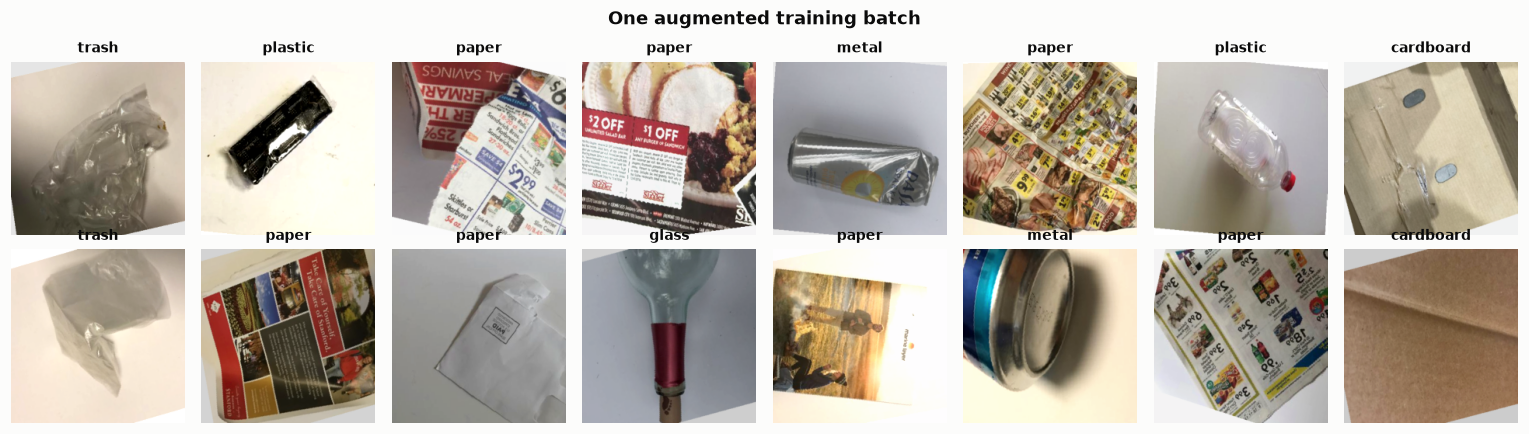

In [14]:
def denormalize(x):
    return (x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()

xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denormalize(x)); hide_axes(ax); ax.set_title(CLASSES[y], fontsize=9)
fig.suptitle('One augmented training batch', fontsize=12, fontweight='bold')
plt.tight_layout(); save(fig, '05_augmented_batch'); plt.show()

### 4.2 Handling the class imbalance
The loss of each class is weighted inversely to its frequency in the training split, $w_c = \dfrac{N}{K \cdot n_c}$ (N images, K = 6 classes, $n_c$ images of class c). A misclassified trash image therefore costs about 3× more than a misclassified paper image, which pushes the decision boundary away from the minority class.

A weighted loss was preferred to oversampling: with only ~95 trash training images, oversampling would show the model the same few trash photos several times per epoch and encourage memorisation. Label smoothing (0.1) is added to reduce over-confidence. Section 9 retrains the best model without the weights to measure their effect.

In [15]:
train_counts = np.bincount(train_df['y'], minlength=NUM_CLASSES)
class_weights = torch.tensor(len(train_df) / (NUM_CLASSES * train_counts), dtype=torch.float32)
display(pd.DataFrame({'train images': train_counts, 'loss weight': class_weights.numpy().round(3)}, index=CLASSES).T)

weighted_ce = nn.CrossEntropyLoss(weight=class_weights.to(DEVICE), label_smoothing=0.1)

,glass,paper,cardboard,plastic,metal,trash
train images,348.000,417.000,282.000,336.000,287.000,96.000
loss weight,0.846,0.706,1.044,0.876,1.026,3.066


## 5. Training and evaluation engine
* **Optimiser:** AdamW (Adam with decoupled weight decay).
* **Learning-rate schedule:** one-cycle (warm-up for the first 15 % of steps, then cosine decay), updated every batch.
* **Mixed precision** (bfloat16) on the GPU for speed and memory.
* **Model selection:** after every epoch the model is scored on the validation set; the weights with the best **validation macro-F1** are kept (macro-F1 rather than accuracy, so the trash class matters as much as the others). Training stops early if macro-F1 does not improve for `patience` epochs.
* **Learning curves:** training and validation loss, accuracy and macro-F1 are plotted for every model. Training metrics are measured on *augmented* images, so they can sit below the validation metrics.

In [16]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    """One pass over `loader` (training if an optimizer is given). Returns loss, accuracy, macro-F1."""
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    for x, y in loader:
        x = x.to(DEVICE, non_blocking=True).to(memory_format=torch.channels_last)
        y = y.to(DEVICE, non_blocking=True)
        with torch.set_grad_enabled(training), torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            logits = model(x)
            loss = criterion(logits, y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        total_loss += loss.item() * len(y)
        y_true.append(y.cpu()); y_pred.append(logits.argmax(1).cpu())
    y_true, y_pred = torch.cat(y_true).numpy(), torch.cat(y_pred).numpy()
    return total_loss / len(y_true), accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average='macro')


def fit(model, name, epochs, param_groups, criterion, weight_decay=0.01, patience=10):
    """AdamW + one-cycle LR. Keeps (and saves) the weights with the best validation macro-F1."""
    model = model.to(DEVICE, memory_format=torch.channels_last)
    optimizer = torch.optim.AdamW(param_groups, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=[g['lr'] for g in param_groups], epochs=epochs,
                                                    steps_per_epoch=len(train_loader), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=USE_AMP and AMP_DTYPE == torch.float16)
    history, best_f1, best_state, wait, start = [], -1.0, None, 0, time.time()
    for epoch in range(1, epochs + 1):
        tr = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler)
        va = run_epoch(model, val_loader, criterion)
        history.append(dict(epoch=epoch, train_loss=tr[0], train_acc=tr[1], train_f1=tr[2],
                            val_loss=va[0], val_acc=va[1], val_f1=va[2]))
        improved = va[2] > best_f1
        if improved:
            best_f1, best_state, wait = va[2], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
        print(f'{name} | epoch {epoch:2d}/{epochs} | train loss {tr[0]:.3f} acc {tr[1]:.3f} | '
              f'val loss {va[0]:.3f} acc {va[1]:.3f} macro-F1 {va[2]:.3f}{"  <- best" if improved else ""}')
        if wait >= patience:
            print(f'Early stopping: no validation macro-F1 improvement for {patience} epochs')
            break
    model.load_state_dict(best_state)
    torch.save(best_state, MODEL_DIR / f'{name}.pt')
    pd.DataFrame(history).to_csv(RESULTS_DIR / f'history_{name}.csv', index=False)
    minutes = (time.time() - start) / 60
    print(f'{name}: best validation macro-F1 = {best_f1:.4f} | training time {minutes:.1f} min')
    return model, pd.DataFrame(history), minutes


def head_and_backbone(model, head, backbone_lr, head_lr):
    """Two parameter groups: the new classifier head learns 10x faster than the pre-trained backbone."""
    head_ids = {id(p) for p in head.parameters()}
    return [{'params': [p for p in model.parameters() if id(p) not in head_ids], 'lr': backbone_lr},
            {'params': list(head.parameters()), 'lr': head_lr}]


def classifier_layer(model):
    """The final nn.Linear; its input is the penultimate feature vector."""
    return [m for m in model.modules() if isinstance(m, nn.Linear)][-1]


@torch.no_grad()
def predict(model, loader, features=False):
    """Softmax probabilities and labels (and penultimate features if requested) for a whole loader."""
    model.eval()
    feats, probs, labels = [], [], []
    hook = classifier_layer(model).register_forward_hook(lambda m, inp, out: feats.append(inp[0].float().cpu())) if features else None
    for x, y in loader:
        x = x.to(DEVICE).to(memory_format=torch.channels_last)
        with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            probs.append(model(x).float().softmax(1).cpu())
        labels.append(y)
    if hook:
        hook.remove()
    out = (torch.cat(probs).numpy(), torch.cat(labels).numpy())
    return out + (torch.cat(feats).numpy(),) if features else out


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def plot_history(hist, name, fname):
    """Training vs. validation loss, accuracy and macro-F1 per epoch; the dot marks the epoch that was kept."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    b = hist.val_f1.idxmax()
    for ax, key, label in zip(axes, ('loss', 'acc', 'f1'), ('loss (weighted cross-entropy)', 'accuracy', 'macro-F1')):
        ax.plot(hist.epoch, hist[f'train_{key}'], color=SERIES[0], label='train')
        ax.plot(hist.epoch, hist[f'val_{key}'], color=SERIES[1], label='validation')
        ax.scatter(hist.epoch[b], hist[f'val_{key}'][b], s=60, color=SERIES[1], edgecolor=SURFACE, linewidth=2, zorder=3,
                   label=f'kept (epoch {hist.epoch[b]}): {hist[f"val_{key}"][b]:.3f}')
        ax.set(title=f'{name}: {label.split(" (")[0]}', xlabel='epoch', ylabel=label)
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend(loc='upper right' if key == 'loss' else 'lower right')
    plt.tight_layout(); save(fig, fname); plt.show()


RESULTS = {}   # name -> histories, predictions and metadata

def record(name, model, hist, minutes):
    p_val, y_val = predict(model, val_loader)
    p_test, y_test, f_test = predict(model, test_loader, features=True)
    RESULTS[name] = dict(history=hist, minutes=minutes, params=count_params(model),
                         p_val=p_val, y_val=y_val, p_test=p_test, y_test=y_test, f_test=f_test)
    print(f'{name}: validation accuracy {accuracy_score(y_val, p_val.argmax(1)):.4f}, '
          f'validation macro-F1 {f1_score(y_val, p_val.argmax(1), average="macro"):.4f}')

## 6. Model A: custom CNN trained from scratch (*WasteNet*)
A VGG-style design built for 224 × 224 inputs:

* **5 convolutional stages.** Each stage is two 3 × 3 convolutions, each followed by **batch normalisation** and **ReLU**, then 2 × 2 **max-pooling**. Channels grow 32 → 64 → 128 → 256 → 384 while the spatial size halves 224 → 7. Stacked 3 × 3 convolutions give a large receptive field with few parameters; batch normalisation stabilises training from random initialisation.
* **Global average pooling** instead of flattening: the 7 × 7 × 384 map becomes a 384-d vector. This keeps the parameter count small (~3 M) and limits overfitting on ~1.8 k training images.
* **Dropout (0.4) and a linear layer** produce the 6 class scores (logits).

In [17]:
def conv_bn_relu(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))

class WasteNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, widths=(32, 64, 128, 256, 384), dropout=0.4):
        super().__init__()
        stages, c_in = [], 3
        for w in widths:
            stages.append(nn.Sequential(conv_bn_relu(c_in, w), conv_bn_relu(w, w), nn.MaxPool2d(2)))
            c_in = w
        self.features = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c_in, num_classes))

    def forward(self, x):
        return self.classifier(self.pool(self.features(x)))

def layer_table(model, blocks):
    """Output shape and parameter count of each block for one dummy 224 x 224 image."""
    rows, x = [], torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)
    model.eval()
    with torch.no_grad():
        for name, block in blocks:
            x = block(x)
            rows.append({'block': name, 'output shape (C, H, W)': tuple(x.shape[1:]),
                         'parameters': sum(p.numel() for p in block.parameters())})
    return pd.DataFrame(rows)

seed_everything()
wastenet = WasteNet()
blocks = [(f'stage {i + 1}: 2 x [conv3x3-BN-ReLU] + maxpool', s) for i, s in enumerate(wastenet.features)]
blocks += [('global average pool', wastenet.pool), ('dropout + linear', wastenet.classifier)]
display(layer_table(wastenet, blocks))
print(f'Total trainable parameters: {count_params(wastenet):,}')

,block,"output shape (C, H, W)",parameters
0,stage 1: 2 x [conv3x3-BN-ReLU] + maxpool,"(32, 112, 112)",10208
1,stage 2: 2 x [conv3x3-BN-ReLU] + maxpool,"(64, 56, 56)",55552
2,stage 3: 2 x [conv3x3-BN-ReLU] + maxpool,"(128, 28, 28)",221696
3,stage 4: 2 x [conv3x3-BN-ReLU] + maxpool,"(256, 14, 14)",885760
4,stage 5: 2 x [conv3x3-BN-ReLU] + maxpool,"(384, 7, 7)",2213376
5,global average pool,"(384, 1, 1)",0
6,dropout + linear,"(6,)",2310


Total trainable parameters: 3,388,902


Trained from random weights it needs many more epochs than a pre-trained network: __EPOCHS_A__ epochs, peak learning rate 3e-3, weight decay 0.05.

In [18]:
seed_everything()
model_a = WasteNet()
model_a, hist_a, minutes_a = fit(model_a, 'WasteNet', epochs=60, criterion=weighted_ce,
                                 param_groups=[{'params': list(model_a.parameters()), 'lr': 3e-3}],
                                 weight_decay=0.05, patience=15)
record('WasteNet', model_a, hist_a, minutes_a)

WasteNet | epoch  1/60 | train loss 1.610 acc 0.400 | val loss 1.539 acc 0.451 macro-F1 0.407  <- best


WasteNet | epoch  2/60 | train loss 1.543 acc 0.441 | val loss 1.508 acc 0.448 macro-F1 0.430  <- best


WasteNet | epoch  3/60 | train loss 1.529 acc 0.460 | val loss 1.697 acc 0.401 macro-F1 0.375


WasteNet | epoch  4/60 | train loss 1.519 acc 0.456 | val loss 1.810 acc 0.347 macro-F1 0.344


WasteNet | epoch  5/60 | train loss 1.576 acc 0.430 | val loss 1.547 acc 0.451 macro-F1 0.439  <- best


...

WasteNet | epoch 57/60 | train loss 0.941 acc 0.793 | val loss 1.004 acc 0.751 macro-F1 0.733


WasteNet | epoch 58/60 | train loss 0.947 acc 0.777 | val loss 1.004 acc 0.759 macro-F1 0.742


WasteNet | epoch 59/60 | train loss 0.951 acc 0.790 | val loss 1.001 acc 0.761 macro-F1 0.742


WasteNet | epoch 60/60 | train loss 0.936 acc 0.788 | val loss 1.002 acc 0.761 macro-F1 0.743
WasteNet: best validation macro-F1 = 0.7498 | training time 5.8 min


WasteNet: validation accuracy 0.7692, validation macro-F1 0.7498


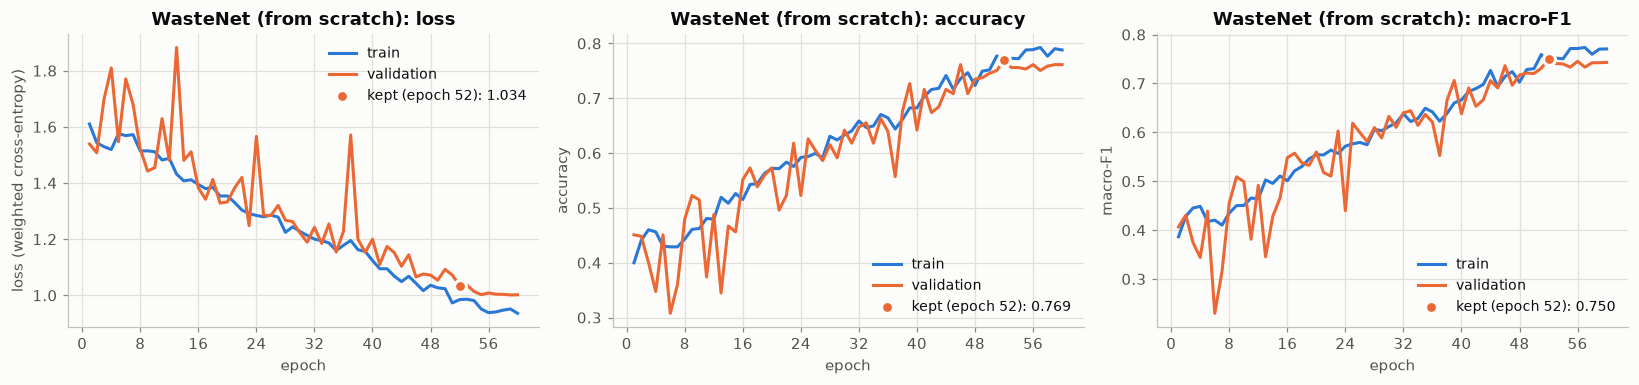

In [19]:
plot_history(hist_a, 'WasteNet (from scratch)', '06_history_wastenet')

## 7. Model B: ResNet-50 with transfer learning
**Transfer learning:** a network pre-trained on ImageNet (1.28 M images, 1,000 classes) already detects edges, textures and shapes. These generic features transfer to waste photos, so far less data is needed than when training from scratch.

ResNet-50 has 50 layers organised in *bottleneck residual blocks*. Each block adds its input back to its output (a **skip connection**), so gradients flow directly through very deep networks. The 1000-way ImageNet classifier is replaced by `Dropout(0.3) → Linear(2048, 6)`, and the **whole network is fine-tuned** with discriminative learning rates: 2e-4 for the pre-trained backbone (adjusted gently) and 2e-3 for the new head (learned from zero).

In [20]:
def build_resnet50():
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))
    return m, m.fc

seed_everything()
model_b, head_b = build_resnet50()
print(f'ResNet-50 parameters: {count_params(model_b):,}')
model_b, hist_b, minutes_b = fit(model_b, 'ResNet-50', epochs=25, criterion=weighted_ce,
                                 param_groups=head_and_backbone(model_b, head_b, 2e-4, 2e-3), patience=10)
record('ResNet-50', model_b, hist_b, minutes_b)

ResNet-50 parameters: 23,520,326


ResNet-50 | epoch  1/25 | train loss 1.748 acc 0.385 | val loss 1.533 acc 0.676 macro-F1 0.654  <- best


ResNet-50 | epoch  2/25 | train loss 1.143 acc 0.736 | val loss 0.923 acc 0.833 macro-F1 0.804  <- best


ResNet-50 | epoch  3/25 | train loss 0.778 acc 0.880 | val loss 0.837 acc 0.891 macro-F1 0.876  <- best


ResNet-50 | epoch  4/25 | train loss 0.729 acc 0.907 | val loss 0.809 acc 0.897 macro-F1 0.888  <- best


...

ResNet-50 | epoch 22/25 | train loss 0.516 acc 1.000 | val loss 0.670 acc 0.947 macro-F1 0.942


ResNet-50 | epoch 23/25 | train loss 0.517 acc 0.999 | val loss 0.672 acc 0.947 macro-F1 0.943  <- best


ResNet-50 | epoch 24/25 | train loss 0.516 acc 0.999 | val loss 0.675 acc 0.939 macro-F1 0.932


ResNet-50 | epoch 25/25 | train loss 0.516 acc 0.999 | val loss 0.671 acc 0.950 macro-F1 0.944  <- best
ResNet-50: best validation macro-F1 = 0.9442 | training time 3.6 min


ResNet-50: validation accuracy 0.9496, validation macro-F1 0.9442


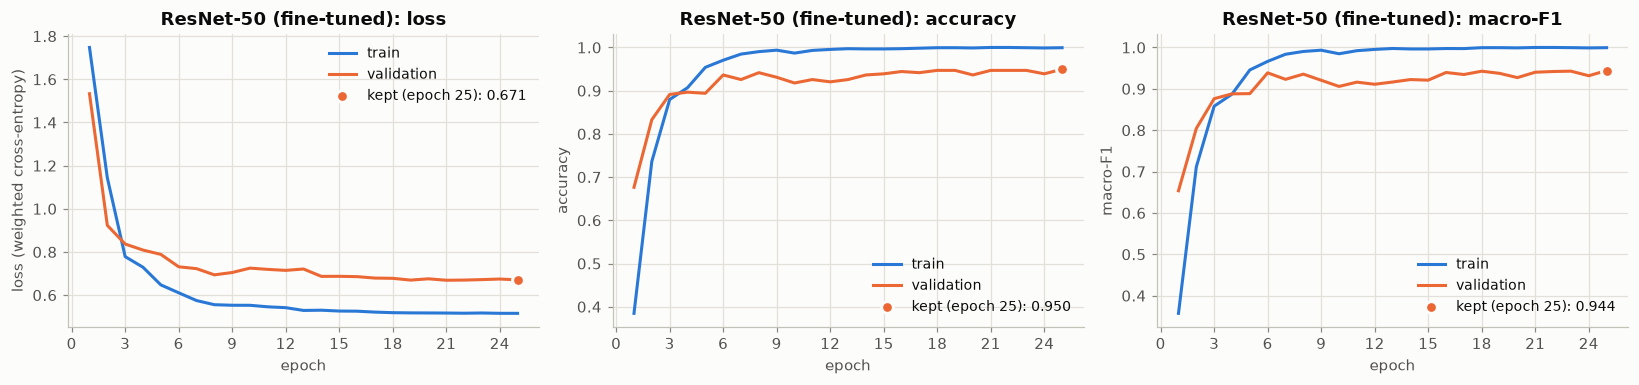

In [21]:
plot_history(hist_b, 'ResNet-50 (fine-tuned)', '07_history_resnet50')

## 8. Model C: EfficientNet-B0 with transfer learning
EfficientNet-B0 is built from **MBConv** blocks: inverted residuals with depthwise-separable convolutions plus *squeeze-and-excitation* channel attention. Its depth, width and resolution were scaled together. It has ~5 M parameters (about 1/5 of ResNet-50) and needs roughly 10× fewer FLOPs, which makes it a realistic candidate for an embedded smart-bin controller. Same recipe as Model B: new head, full fine-tuning, discriminative learning rates (5e-4 backbone / 3e-3 head).

In [22]:
def build_efficientnet_b0():
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[1].in_features, NUM_CLASSES))
    return m, m.classifier

seed_everything()
model_c, head_c = build_efficientnet_b0()
print(f'EfficientNet-B0 parameters: {count_params(model_c):,}')
model_c, hist_c, minutes_c = fit(model_c, 'EfficientNet-B0', epochs=25, criterion=weighted_ce,
                                 param_groups=head_and_backbone(model_c, head_c, 5e-4, 3e-3), patience=10)
record('EfficientNet-B0', model_c, hist_c, minutes_c)

EfficientNet-B0 parameters: 4,015,234


EfficientNet-B0 | epoch  1/25 | train loss 1.665 acc 0.401 | val loss 1.335 acc 0.711 macro-F1 0.685  <- best


EfficientNet-B0 | epoch  2/25 | train loss 1.076 acc 0.745 | val loss 0.966 acc 0.812 macro-F1 0.789  <- best


EfficientNet-B0 | epoch  3/25 | train loss 0.831 acc 0.856 | val loss 0.906 acc 0.857 macro-F1 0.822  <- best


EfficientNet-B0 | epoch  4/25 | train loss 0.769 acc 0.887 | val loss 0.836 acc 0.891 macro-F1 0.868  <- best


...

EfficientNet-B0 | epoch 22/25 | train loss 0.528 acc 0.997 | val loss 0.689 acc 0.947 macro-F1 0.936


EfficientNet-B0 | epoch 23/25 | train loss 0.528 acc 0.998 | val loss 0.686 acc 0.950 macro-F1 0.943


EfficientNet-B0 | epoch 24/25 | train loss 0.527 acc 0.998 | val loss 0.682 acc 0.950 macro-F1 0.942


EfficientNet-B0 | epoch 25/25 | train loss 0.529 acc 0.999 | val loss 0.683 acc 0.952 macro-F1 0.948
EfficientNet-B0: best validation macro-F1 = 0.9500 | training time 3.0 min


EfficientNet-B0: validation accuracy 0.9523, validation macro-F1 0.9500


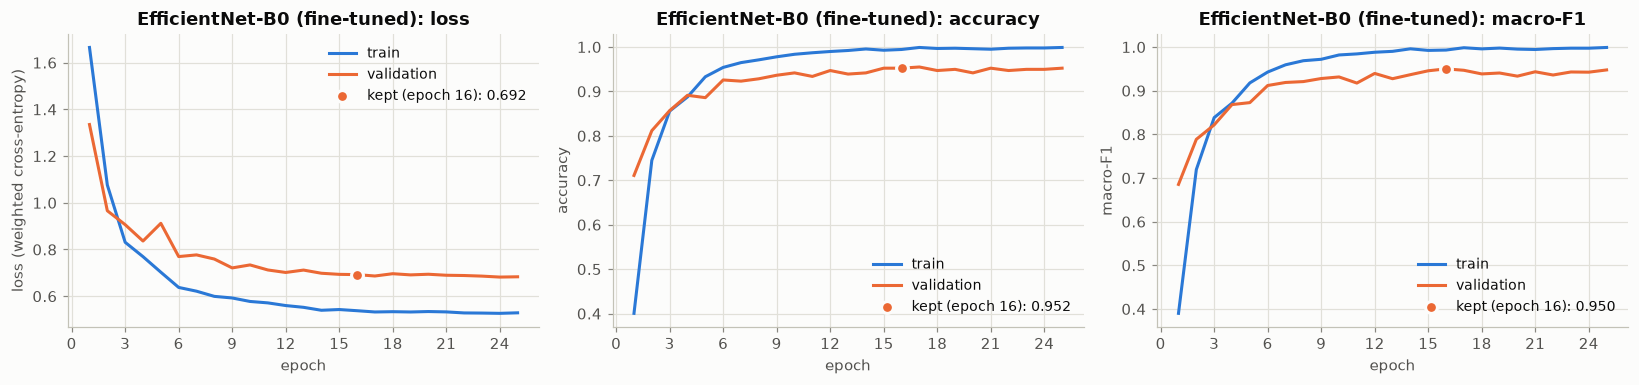

In [23]:
plot_history(hist_c, 'EfficientNet-B0 (fine-tuned)', '08_history_efficientnet_b0')

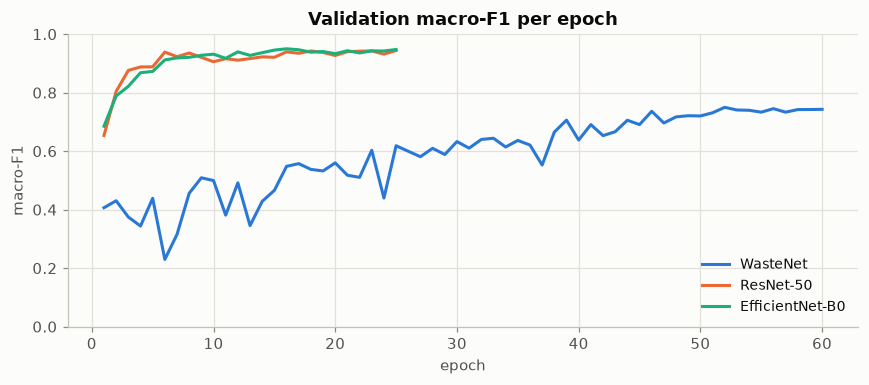

In [24]:
MAIN_MODELS = ['WasteNet', 'ResNet-50', 'EfficientNet-B0']
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, name in enumerate(MAIN_MODELS):
    h = RESULTS[name]['history']
    ax.plot(h.epoch, h.val_f1, color=SERIES[k], label=name)
ax.set(title='Validation macro-F1 per epoch', xlabel='epoch', ylabel='macro-F1', ylim=(0, 1))
ax.legend(loc='lower right')
plt.tight_layout(); save(fig, '09_val_f1_all_models'); plt.show()

**Observations (training)**

* **WasteNet (from scratch)** reaches validation macro-F1 **0.75** (best epoch 52 of 60). Training and validation accuracy stay close (0.79 vs 0.76 at the end) and the validation loss is still falling at epoch 59. The model is **under-fitting / data-limited**, not over-fitting: about 1,800 images are not enough to learn strong visual features from random weights.
* **ResNet-50** and **EfficientNet-B0** converge within about 6 epochs, because ImageNet features already describe shape, texture and gloss. They reach validation macro-F1 **0.944** and **0.950**.
* **Over-fitting check (pre-trained models):** training accuracy goes to ≈ 1.00 while validation accuracy plateaus at ≈ 0.95, a ~5-point gap. The validation loss does not rise (its minimum is at epochs 21–24), so the gap is mild memorisation rather than harmful over-fitting. It is kept in check by augmentation, dropout, weight decay, label smoothing and by keeping the weights from the best validation epoch (epoch 16 for EfficientNet-B0).
* Training time on the RTX 4050: 5.8 min (WasteNet, 60 epochs), 3.6 min (ResNet-50), 3.0 min (EfficientNet-B0).

## 9. Ablation: does the class-weighted loss help the trash class?
The pre-trained model with the higher **validation** macro-F1 is retrained with exactly the same seed, data order and hyper-parameters, but with an **unweighted** cross-entropy loss. Any difference in trash recall / F1 can then be attributed to the class weights.

In [25]:
BEST = max(['ResNet-50', 'EfficientNet-B0'], key=lambda n: f1_score(RESULTS[n]['y_val'], RESULTS[n]['p_val'].argmax(1), average='macro'))
print('Best pre-trained model on validation macro-F1:', BEST)

builder, lrs, epochs = {'ResNet-50': (build_resnet50, (2e-4, 2e-3), 25),
                        'EfficientNet-B0': (build_efficientnet_b0, (5e-4, 3e-3), 25)}[BEST]
ABLATION = f'{BEST} (unweighted loss)'
seed_everything()
model_u, head_u = builder()
model_u, hist_u, minutes_u = fit(model_u, ABLATION.replace(' ', '_'), epochs=epochs,
                                 criterion=nn.CrossEntropyLoss(label_smoothing=0.1),
                                 param_groups=head_and_backbone(model_u, head_u, *lrs), patience=10)
record(ABLATION, model_u, hist_u, minutes_u)
model_u.cpu(); torch.cuda.empty_cache()

Best pre-trained model on validation macro-F1: EfficientNet-B0


EfficientNet-B0_(unweighted_loss) | epoch  1/25 | train loss 1.587 acc 0.427 | val loss 1.187 acc 0.711 macro-F1 0.632  <- best


EfficientNet-B0_(unweighted_loss) | epoch  2/25 | train loss 0.965 acc 0.755 | val loss 0.754 acc 0.867 macro-F1 0.830  <- best


EfficientNet-B0_(unweighted_loss) | epoch  3/25 | train loss 0.732 acc 0.874 | val loss 0.712 acc 0.894 macro-F1 0.874  <- best


EfficientNet-B0_(unweighted_loss) | epoch  4/25 | train loss 0.657 acc 0.906 | val loss 0.677 acc 0.926 macro-F1 0.909  <- best


...

EfficientNet-B0_(unweighted_loss) | epoch 22/25 | train loss 0.448 acc 0.998 | val loss 0.571 acc 0.931 macro-F1 0.916


EfficientNet-B0_(unweighted_loss) | epoch 23/25 | train loss 0.447 acc 0.998 | val loss 0.564 acc 0.939 macro-F1 0.936


EfficientNet-B0_(unweighted_loss) | epoch 24/25 | train loss 0.445 acc 0.997 | val loss 0.565 acc 0.931 macro-F1 0.923


EfficientNet-B0_(unweighted_loss) | epoch 25/25 | train loss 0.446 acc 0.999 | val loss 0.566 acc 0.931 macro-F1 0.919
Early stopping: no validation macro-F1 improvement for 10 epochs
EfficientNet-B0_(unweighted_loss): best validation macro-F1 = 0.9376 | training time 2.7 min


EfficientNet-B0 (unweighted loss): validation accuracy 0.9416, validation macro-F1 0.9376


## 10. Test-set evaluation
### 10.1 Overall metrics
| Metric | Meaning |
|---|---|
| Accuracy | share of correctly classified images, dominated by the large classes |
| Balanced accuracy | mean of per-class recall (= macro recall); every class counts equally |
| Macro precision / F1 | unweighted mean over the 6 classes, so the trash class weighs as much as paper |
| Weighted F1 | F1 averaged with class-size weights |
| Cohen's κ | agreement beyond chance (1 = perfect, 0 = chance level) |
| Top-2 accuracy | true class among the 2 highest-scoring classes (useful when a second sorting stage exists) |
| Macro ROC-AUC | one-vs-rest ranking quality, independent of the decision threshold |

With only ~20 trash images in the test set, one image changes trash recall by about 5 percentage points. **95 % bootstrap confidence intervals** (2,000 resamples of the test set) are therefore reported for the key numbers.

In [26]:
def evaluate(y, prob):
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=range(NUM_CLASSES), zero_division=0)
    return {'accuracy': accuracy_score(y, pred), 'balanced_acc': balanced_accuracy_score(y, pred),
            'macro_precision': p.mean(), 'macro_f1': f.mean(), 'weighted_f1': f1_score(y, pred, average='weighted'),
            'cohen_kappa': cohen_kappa_score(y, pred),
            'top2_acc': top_k_accuracy_score(y, prob, k=2, labels=range(NUM_CLASSES)),
            'macro_roc_auc': roc_auc_score(y, prob, multi_class='ovr', average='macro'),
            'trash_precision': p[TRASH], 'trash_recall': r[TRASH], 'trash_f1': f[TRASH]}

def bootstrap(y, pred, n=2000, seed=SEED):
    """Per-class F1, trash recall and accuracy for n bootstrap resamples of the test set."""
    rng = np.random.default_rng(seed)
    f1s, trash_rec, acc = [], [], []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        f1s.append(f1_score(y[i], pred[i], labels=range(NUM_CLASSES), average=None, zero_division=0))
        m = y[i] == TRASH
        trash_rec.append((pred[i][m] == TRASH).mean())
        acc.append((y[i] == pred[i]).mean())
    return np.array(f1s), np.array(trash_rec), np.array(acc)

def ci(samples):
    lo, hi = np.nanpercentile(samples, [2.5, 97.5])
    return f'[{lo:.3f}, {hi:.3f}]'

rows, BOOT = {}, {}
for name, r in RESULTS.items():
    rows[name] = evaluate(r['y_test'], r['p_test'])
    BOOT[name] = bootstrap(r['y_test'], r['p_test'].argmax(1))
metrics_table = pd.DataFrame(rows).T
display(metrics_table.round(3))

ci_table = pd.DataFrame({name: {'accuracy 95% CI': ci(BOOT[name][2]), 'macro-F1 95% CI': ci(BOOT[name][0].mean(1)),
                                'trash recall 95% CI': ci(BOOT[name][1]), 'trash F1 95% CI': ci(BOOT[name][0][:, TRASH])}
                         for name in RESULTS}).T
display(ci_table)
metrics_table.to_csv(RESULTS_DIR / 'test_metrics.csv')

,accuracy,balanced_acc,macro_precision,macro_f1,weighted_f1,cohen_kappa,top2_acc,macro_roc_auc,trash_precision,trash_recall,trash_f1
WasteNet,0.817,0.829,0.796,0.799,0.822,0.778,0.934,0.975,0.486,0.90,0.632
ResNet-50,0.968,0.966,0.967,0.966,0.968,0.961,0.984,0.996,0.950,0.95,0.950
EfficientNet-B0,0.950,0.949,0.947,0.947,0.950,0.938,0.968,0.996,0.905,0.95,0.927
EfficientNet-B0 (unweighted loss),0.955,0.955,0.956,0.955,0.955,0.945,0.984,0.996,0.950,0.95,0.950


,accuracy 95% CI,macro-F1 95% CI,trash recall 95% CI,trash F1 95% CI
WasteNet,"[0.778, 0.857]","[0.754, 0.843]","[0.750, 1.000]","[0.467, 0.767]"
ResNet-50,"[0.950, 0.984]","[0.943, 0.984]","[0.833, 1.000]","[0.864, 1.000]"
EfficientNet-B0,"[0.926, 0.971]","[0.920, 0.969]","[0.833, 1.000]","[0.826, 1.000]"
EfficientNet-B0 (unweighted loss),"[0.931, 0.976]","[0.929, 0.976]","[0.833, 1.000]","[0.864, 1.000]"


### 10.2 Per-class results of the selected model
The final model is chosen by **validation** macro-F1 among the three main models, not by test score, so the test estimate stays unbiased.

In [27]:
FINAL = max(MAIN_MODELS, key=lambda n: f1_score(RESULTS[n]['y_val'], RESULTS[n]['p_val'].argmax(1), average='macro'))
y_test, p_test = RESULTS[FINAL]['y_test'], RESULTS[FINAL]['p_test']
pred_test = p_test.argmax(1)
print(f'Selected model: {FINAL}\n')

p, r, f, s = precision_recall_fscore_support(y_test, pred_test, labels=range(NUM_CLASSES), zero_division=0)
lo, hi = np.percentile(BOOT[FINAL][0], [2.5, 97.5], axis=0)
per_class = pd.DataFrame({'precision': p, 'recall': r, 'F1': f, 'F1 95% CI': [f'[{a:.2f}, {b:.2f}]' for a, b in zip(lo, hi)],
                          'support (test images)': s}, index=CLASSES)
per_class.loc['macro avg'] = [p.mean(), r.mean(), f.mean(), ci(BOOT[FINAL][0].mean(1)), s.sum()]
display(per_class.round(3))
per_class.to_csv(RESULTS_DIR / 'per_class_final_model.csv')

Selected model: EfficientNet-B0



,precision,recall,F1,F1 95% CI,support (test images)
glass,0.937,0.987,0.961,"[0.93, 0.99]",75
paper,0.945,0.966,0.956,"[0.92, 0.98]",89
cardboard,1.000,0.918,0.957,"[0.91, 0.99]",61
plastic,0.985,0.889,0.934,"[0.89, 0.97]",72
metal,0.909,0.984,0.945,"[0.90, 0.98]",61
trash,0.905,0.950,0.927,"[0.83, 1.00]",20
macro avg,0.947,0.949,0.947,"[0.920, 0.969]",378


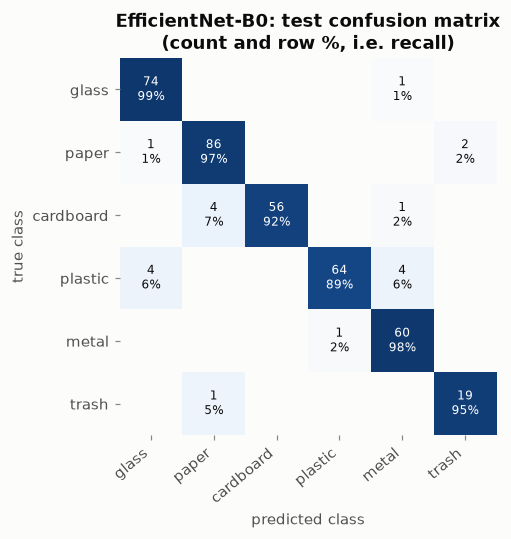

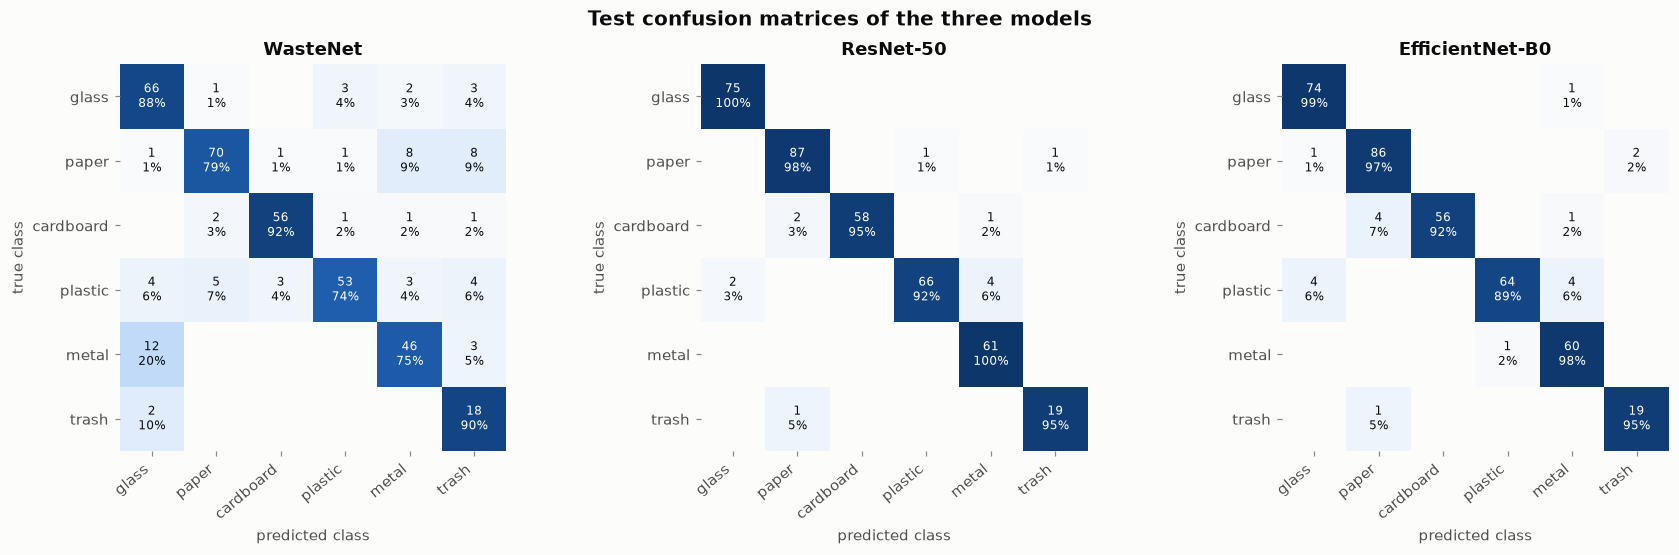

In [28]:
def plot_confusion(ax, y, pred, title, fontsize=8, show_share=True):
    """Row-normalised confusion matrix: colour = share of the true class, text = count (and share)."""
    cm = confusion_matrix(y, pred, labels=range(NUM_CLASSES))
    share = cm / cm.sum(1, keepdims=True)
    ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            if cm[i, j]:
                ax.text(j, i, f'{cm[i, j]}\n{share[i, j]:.0%}' if show_share else f'{cm[i, j]}', ha='center', va='center',
                        fontsize=fontsize, color='white' if share[i, j] > 0.45 else INK)
    ax.set_xticks(range(NUM_CLASSES), CLASSES, rotation=40, ha='right')
    ax.set_yticks(range(NUM_CLASSES), CLASSES)
    ax.set(xlabel='predicted class', ylabel='true class', title=title)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return cm

fig, ax = plt.subplots(figsize=(5.6, 5))
cm_final = plot_confusion(ax, y_test, pred_test, f'{FINAL}: test confusion matrix\n(count and row %, i.e. recall)')
plt.tight_layout(); save(fig, '10_confusion_final'); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, name in zip(axes, MAIN_MODELS):
    plot_confusion(ax, RESULTS[name]['y_test'], RESULTS[name]['p_test'].argmax(1), name)
fig.suptitle('Test confusion matrices of the three models', fontsize=13, fontweight='bold')
plt.tight_layout(); save(fig, '11_confusion_all_models'); plt.show()

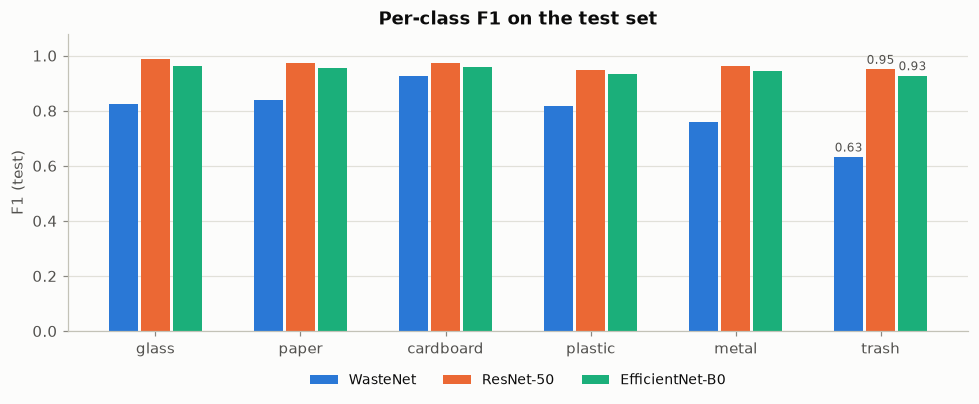

In [29]:
fig, ax = plt.subplots(figsize=(9, 3.8))
x, w = np.arange(NUM_CLASSES), 0.2
for k, name in enumerate(MAIN_MODELS):
    f1_c = f1_score(RESULTS[name]['y_test'], RESULTS[name]['p_test'].argmax(1), labels=range(NUM_CLASSES), average=None)
    ax.bar(x + (k - 1) * (w + 0.02), f1_c, width=w, color=SERIES[k], label=name)
    ax.text(x[TRASH] + (k - 1) * (w + 0.02), f1_c[TRASH] + 0.02, f'{f1_c[TRASH]:.2f}', ha='center', fontsize=8, color=INK_2)
ax.set_xticks(x, CLASSES)
ax.set(ylim=(0, 1.08), ylabel='F1 (test)', title='Per-class F1 on the test set')
ax.grid(axis='x', visible=False)
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))
plt.tight_layout(); save(fig, '12_per_class_f1'); plt.show()

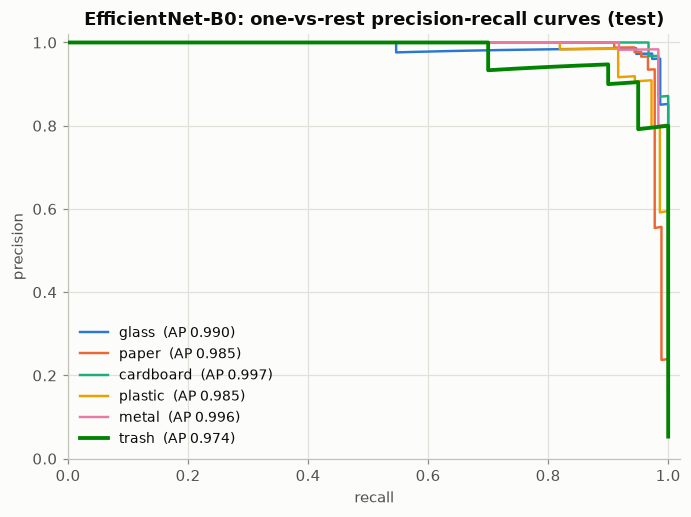

In [30]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
for i, c in enumerate(CLASSES):
    prec, rec, _ = precision_recall_curve(y_test == i, p_test[:, i])
    ap = average_precision_score(y_test == i, p_test[:, i])
    ax.plot(rec, prec, color=CLASS_COLOR[c], lw=2.5 if c == 'trash' else 1.6, label=f'{c}  (AP {ap:.3f})',
            zorder=3 if c == 'trash' else 2)
ax.set(xlabel='recall', ylabel='precision', title=f'{FINAL}: one-vs-rest precision-recall curves (test)',
       xlim=(0, 1.02), ylim=(0, 1.02))
ax.legend(loc='lower left')
plt.tight_layout(); save(fig, '13_pr_curves'); plt.show()

### 10.3 Effect of the class-weighted loss (ablation result)

,accuracy,macro_f1,trash_precision,trash_recall,trash_f1
EfficientNet-B0,0.950,0.947,0.905,0.95,0.927
EfficientNet-B0 (unweighted loss),0.955,0.955,0.950,0.95,0.950


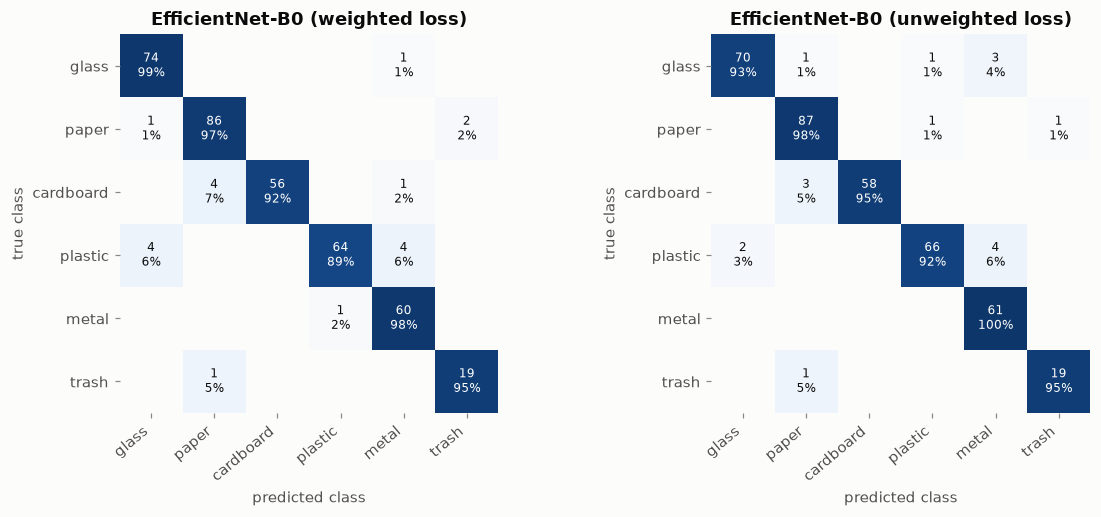

In [31]:
cols = ['accuracy', 'macro_f1', 'trash_precision', 'trash_recall', 'trash_f1']
display(metrics_table.loc[[BEST, ABLATION], cols].round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, name in zip(axes, (BEST, ABLATION)):
    plot_confusion(ax, RESULTS[name]['y_test'], RESULTS[name]['p_test'].argmax(1),
                   name if name == ABLATION else f'{name} (weighted loss)')
plt.tight_layout(); save(fig, '14_ablation_confusion'); plt.show()

**Observations (evaluation)**

* **Selected model: EfficientNet-B0**, chosen on *validation* macro-F1 (0.950 vs. 0.944 for ResNet-50). Test results: **accuracy 0.95, macro-F1 0.95 (95 % CI 0.92–0.97), trash precision 0.90, recall 0.95, F1 0.93**.
* ResNet-50 scored slightly higher on the test set (accuracy 0.97, macro-F1 0.97). Switching to it *after* looking at test scores would turn the test set into a selection set, and the two confidence intervals overlap (0.94–0.98 vs. 0.92–0.97), so the difference is not significant. EfficientNet-B0 is also **6× smaller and 2.5× faster on CPU** (see Section 12).
* **Transfer learning is the decisive factor:** macro-F1 rises from 0.80 (scratch CNN) to 0.95–0.97, and trash F1 from 0.63 to 0.93–0.95.
* The class-weighted loss made the **scratch CNN over-predict trash** (trash recall 0.90 but precision only 0.49).
* **Ablation (Section 9 / 10.3):** without class weights, EfficientNet-B0 scored test macro-F1 0.955 and trash F1 0.95 (19/20 trash found, 1 false alarm), vs. 0.947 and 0.93 with weights (19/20 found, 2 false alarms). On *validation* the weighted model was better (0.950 vs. 0.938). The differences amount to 1–3 images and lie well inside the bootstrap CIs. **Conclusion: for a pre-trained network the weighting has no measurable effect**, because the ImageNet features already separate trash well (see the t-SNE in Section 11). Weighting matters when features are weak, as with the scratch CNN, and there it trades precision for recall.
* **Hardest recyclable classes:** plastic (recall 0.89: 4 → glass, 4 → metal) and cardboard (recall 0.92: 4 → paper). Macro ROC-AUC is 0.996, so the classes are ranked almost perfectly; the remaining errors are genuinely ambiguous items (next section).

### 10.4 Misclassified test images
Eight misclassified test images of the selected model. At most two are taken per (true → predicted) pair, starting with the most frequent confusions, so that the gallery covers several kinds of error. The likely reason for each error is given in the table below the figure.

EfficientNet-B0: 19 of 378 test images misclassified


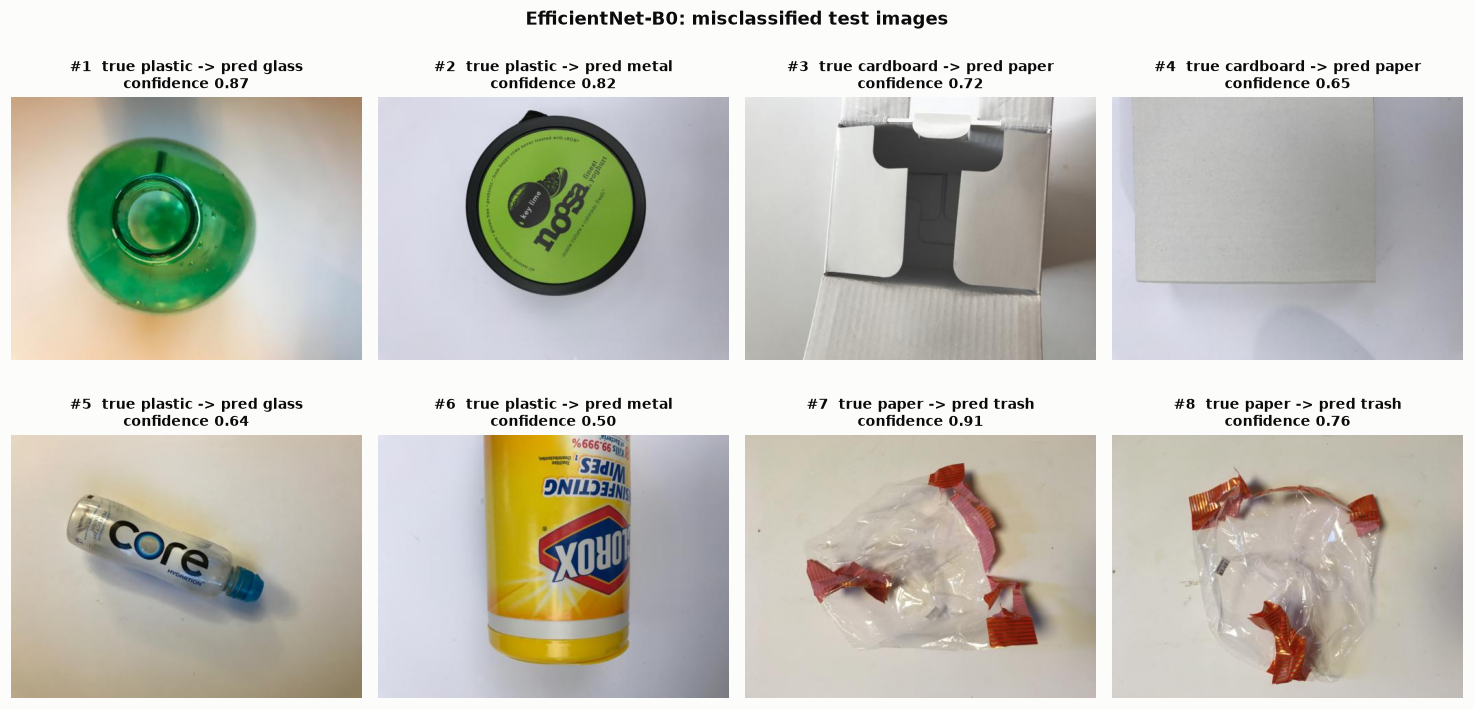

,file,true,predicted,confidence,P(true class)
#,,,,,
1,plastic441.jpg,plastic,glass,0.87,0.03
2,plastic307.jpg,plastic,metal,0.82,0.04
3,cardboard294.jpg,cardboard,paper,0.72,0.08
4,cardboard296.jpg,cardboard,paper,0.65,0.10
5,plastic266.jpg,plastic,glass,0.64,0.09
6,plastic356.jpg,plastic,metal,0.50,0.12
7,paper590.jpg,paper,trash,0.91,0.02
8,paper591.jpg,paper,trash,0.76,0.00


In [32]:
err = np.where(pred_test != y_test)[0]
pair_count = pd.Series(list(zip(y_test[err], pred_test[err]))).value_counts()
err = sorted(err, key=lambda i: (-pair_count[(y_test[i], pred_test[i])], -p_test[i].max()))
picked, per_pair = [], {}
for i in err:
    pair = (y_test[i], pred_test[i])
    if per_pair.get(pair, 0) < 2:
        picked.append(i); per_pair[pair] = per_pair.get(pair, 0) + 1
    if len(picked) == 8:
        break
print(f'{FINAL}: {len(err)} of {len(y_test)} test images misclassified')

fig, axes = plt.subplots(2, 4, figsize=(13.5, 7))
for ax in axes.flat:
    hide_axes(ax)
for k, (ax, i) in enumerate(zip(axes.flat, picked), start=1):
    ax.imshow(Image.open(test_df.path[i]))
    ax.set_title(f'#{k}  true {CLASSES[y_test[i]]} -> pred {CLASSES[pred_test[i]]}\n'
                 f'confidence {p_test[i].max():.2f}', fontsize=9)
fig.suptitle(f'{FINAL}: misclassified test images', fontsize=12, fontweight='bold')
plt.tight_layout(); save(fig, '15_misclassified'); plt.show()

display(pd.DataFrame([{'#': k, 'file': Path(test_df.path[i]).name, 'true': CLASSES[y_test[i]],
                       'predicted': CLASSES[pred_test[i]], 'confidence': round(float(p_test[i].max()), 2),
                       'P(true class)': round(float(p_test[i][y_test[i]]), 2)}
                      for k, i in enumerate(picked, start=1)]).set_index('#'))

**Likely reason for each error**

| # | True → predicted (confidence) | Likely reason |
|---|---|---|
| 1 | plastic → glass (0.87) | A **green PET bottle seen from the top**: round neck, green translucent body and specular highlights are exactly the cues of a green glass bottle. Wall thickness, the only real difference, is not visible in a photo. |
| 2 | plastic → metal (0.82) | A **round yoghurt-cup lid with a dark rim**, shot top-down. It has the same circular outline and glossy printed top as the lid of a metal can. |
| 3 | cardboard → paper (0.72) | A **white folding carton (paperboard)**: thin, smooth and white. Most cardboard in the training set is brown corrugated board, so white board looks like paper. |
| 4 | cardboard → paper (0.65) | A **flat grey sheet that fills the frame** with no edge, fold or corrugation visible. Nothing in the image separates it from a sheet of paper, and the confidence is low. |
| 5 | plastic → glass (0.64) | A **transparent water bottle** with a printed label. Transparency and reflections are the strongest glass cues. |
| 6 | plastic → metal (0.50) | A **cylindrical wipes canister** with a printed label filling the frame. It looks like a metal can, and the model is unsure (0.50, close to a coin toss). |
| 7, 8 | paper → trash (0.91, 0.76) | Both photos show the **same crumpled clear plastic bag with red tape**; no paper is visible. This is very likely a **labelling error in TrashNet**, and "trash" is a visually reasonable answer. |

Common pattern: the errors are **material look-alikes**, items whose shape and colour match another class (green or clear plastic vs. glass, plastic lids and canisters vs. metal cans, white paperboard vs. paper). An RGB photo cannot always reveal the material; industrial sorters add near-infrared spectroscopy for exactly this reason.

## 11. Trash-class error analysis
`trash` is a *residual* class: everything that is not one of the five recyclable materials (food wrappers, tissues, mixed-material packaging, cling film, etc.). It is both **small** and **visually heterogeneous**, and many trash items are *made of* plastic or paper. The analyses below show where trash errors go and why.

In [33]:
trash_flow = pd.DataFrame({'true trash predicted as ->': cm_final[TRASH], 'predicted trash, actually ->': cm_final[:, TRASH]},
                          index=CLASSES)
display(trash_flow.T)

off = cm_final.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(-off.ravel()), off.shape))[0][:6]
display(pd.DataFrame([{'true': CLASSES[i], 'predicted': CLASSES[j], 'test images': off[i, j]} for i, j in top if off[i, j]])
        .set_index(['true', 'predicted']))

,glass,paper,cardboard,plastic,metal,trash
true trash predicted as ->,0,1,0,0,0,19
"predicted trash, actually ->",0,2,0,0,0,19


test images
true      predicted             
cardboard paper                4
plastic   glass                4
          metal                4
paper     trash                2
metal     plastic              1
cardboard metal                1

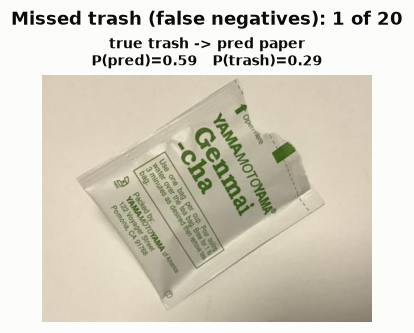

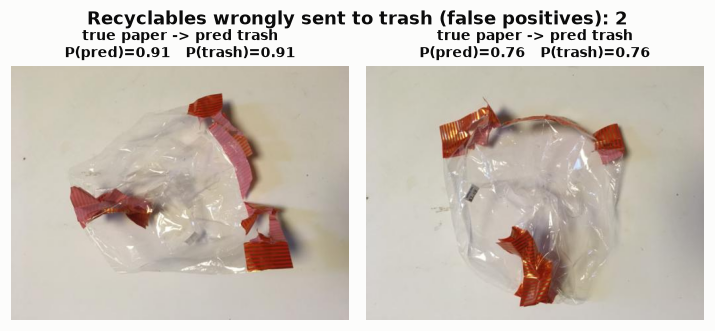

In [34]:
def gallery(idx, title, fname, max_n=8):
    idx = list(idx)[:max_n]
    if not idx:
        print(f'{title}: none in the test set'); return
    cols = min(4, len(idx)); rows_ = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3.3 * cols, 3.1 * rows_), squeeze=False)
    for ax in axes.flat:
        hide_axes(ax)
    for ax, i in zip(axes.flat, idx):
        pr = p_test[i]
        ax.imshow(Image.open(test_df.path[i]))
        ax.set_title(f'true {CLASSES[y_test[i]]} -> pred {CLASSES[pr.argmax()]}\n'
                     f'P(pred)={pr.max():.2f}   P(trash)={pr[TRASH]:.2f}', fontsize=9)
    fig.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout(); save(fig, fname); plt.show()

fn = np.where((y_test == TRASH) & (pred_test != TRASH))[0]
fp = np.where((y_test != TRASH) & (pred_test == TRASH))[0]
gallery(fn[np.argsort(-p_test[fn].max(1))], f'Missed trash (false negatives): {len(fn)} of {(y_test == TRASH).sum()}', '16_trash_false_negatives')
gallery(fp[np.argsort(-p_test[fp, TRASH])], f'Recyclables wrongly sent to trash (false positives): {len(fp)}', '17_trash_false_positives')

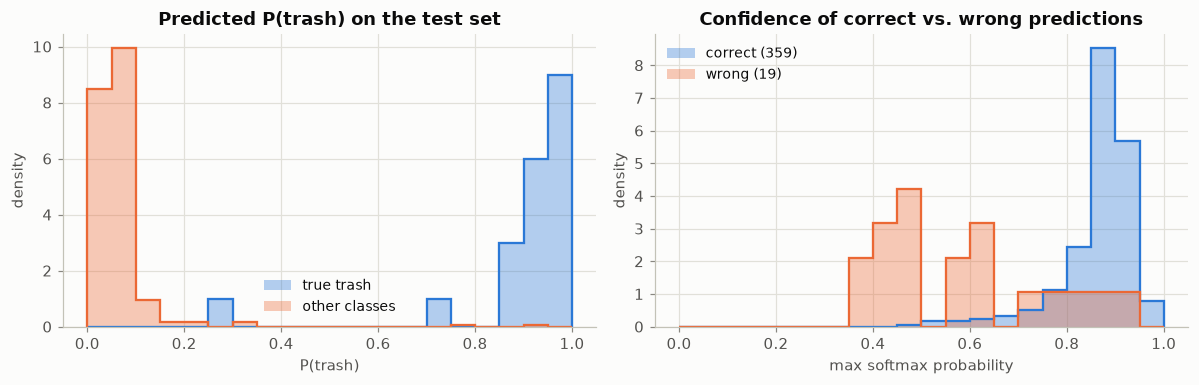

Mean confidence: correct 0.865 | wrong 0.585


In [35]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
bins = np.linspace(0, 1, 21)
for k, (mask, lab) in enumerate(((y_test == TRASH, 'true trash'), (y_test != TRASH, 'other classes'))):
    a1.hist(p_test[mask, TRASH], bins=bins, color=SERIES[k], alpha=0.35, density=True, label=lab)
    a1.hist(p_test[mask, TRASH], bins=bins, color=SERIES[k], histtype='step', lw=1.5, density=True)
a1.set(title='Predicted P(trash) on the test set', xlabel='P(trash)', ylabel='density')
a1.legend()

conf = p_test.max(1)
for k, (mask, lab) in enumerate(((pred_test == y_test, 'correct'), (pred_test != y_test, 'wrong'))):
    a2.hist(conf[mask], bins=bins, color=SERIES[k], alpha=0.35, density=True, label=f'{lab} ({mask.sum()})')
    a2.hist(conf[mask], bins=bins, color=SERIES[k], histtype='step', lw=1.5, density=True)
a2.set(title='Confidence of correct vs. wrong predictions', xlabel='max softmax probability', ylabel='density')
a2.legend(loc='upper left')
plt.tight_layout(); save(fig, '18_confidence'); plt.show()
print(f'Mean confidence: correct {conf[pred_test == y_test].mean():.3f} | wrong {conf[pred_test != y_test].mean():.3f}')

**Feature space (t-SNE).** The 2-D t-SNE projection of the selected model's penultimate-layer features for all test images shows how compact each class is. Tight, separated clusters are easy to classify; trash points scattered among other clusters explain its lower recall.

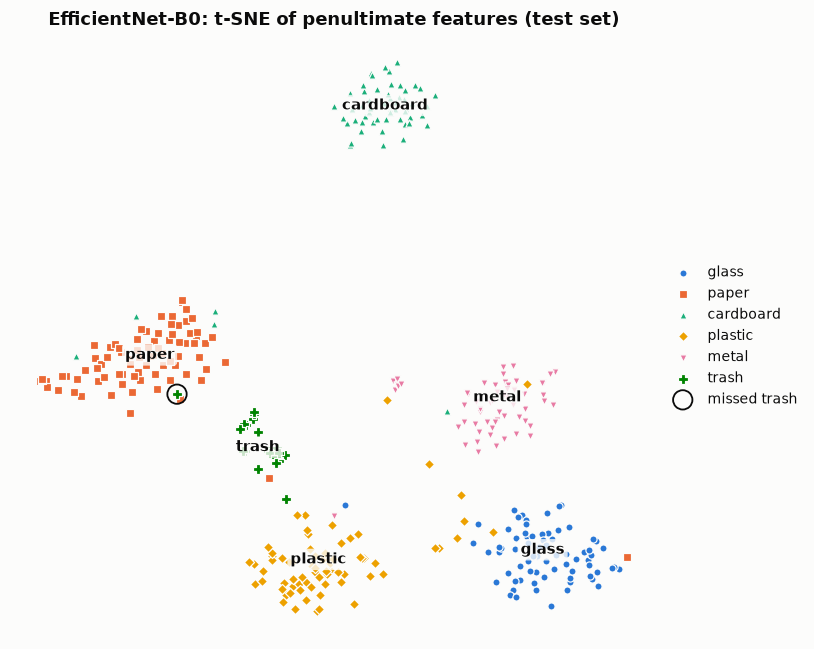

In [36]:
emb = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(RESULTS[FINAL]['f_test'])
fig, ax = plt.subplots(figsize=(7.5, 6))
for i, c in enumerate(CLASSES):
    m = y_test == i
    ax.scatter(emb[m, 0], emb[m, 1], s=46 if c == 'trash' else 22, marker=CLASS_MARKER[c], color=CLASS_COLOR[c],
               edgecolor=SURFACE, linewidth=0.8, label=c, zorder=3 if c == 'trash' else 2)
    cx, cy = np.median(emb[m], axis=0)
    ax.annotate(c, (cx, cy), fontsize=10, fontweight='bold', color=INK, ha='center', zorder=4,
                bbox=dict(boxstyle='round,pad=0.2', fc=SURFACE, ec='none', alpha=0.8))
ax.scatter(emb[fn, 0], emb[fn, 1], s=160, facecolor='none', edgecolor=INK, linewidth=1.2, zorder=4, label='missed trash')
hide_axes(ax)
ax.set_title(f'{FINAL}: t-SNE of penultimate features (test set)')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout(); save(fig, '19_tsne'); plt.show()

**Grad-CAM** shows which image regions drove a prediction. The gradients of the predicted class score with respect to the last convolutional feature map are averaged per channel to obtain channel weights, the weighted sum of the channels is passed through a ReLU and upsampled onto the image (orange = high importance).

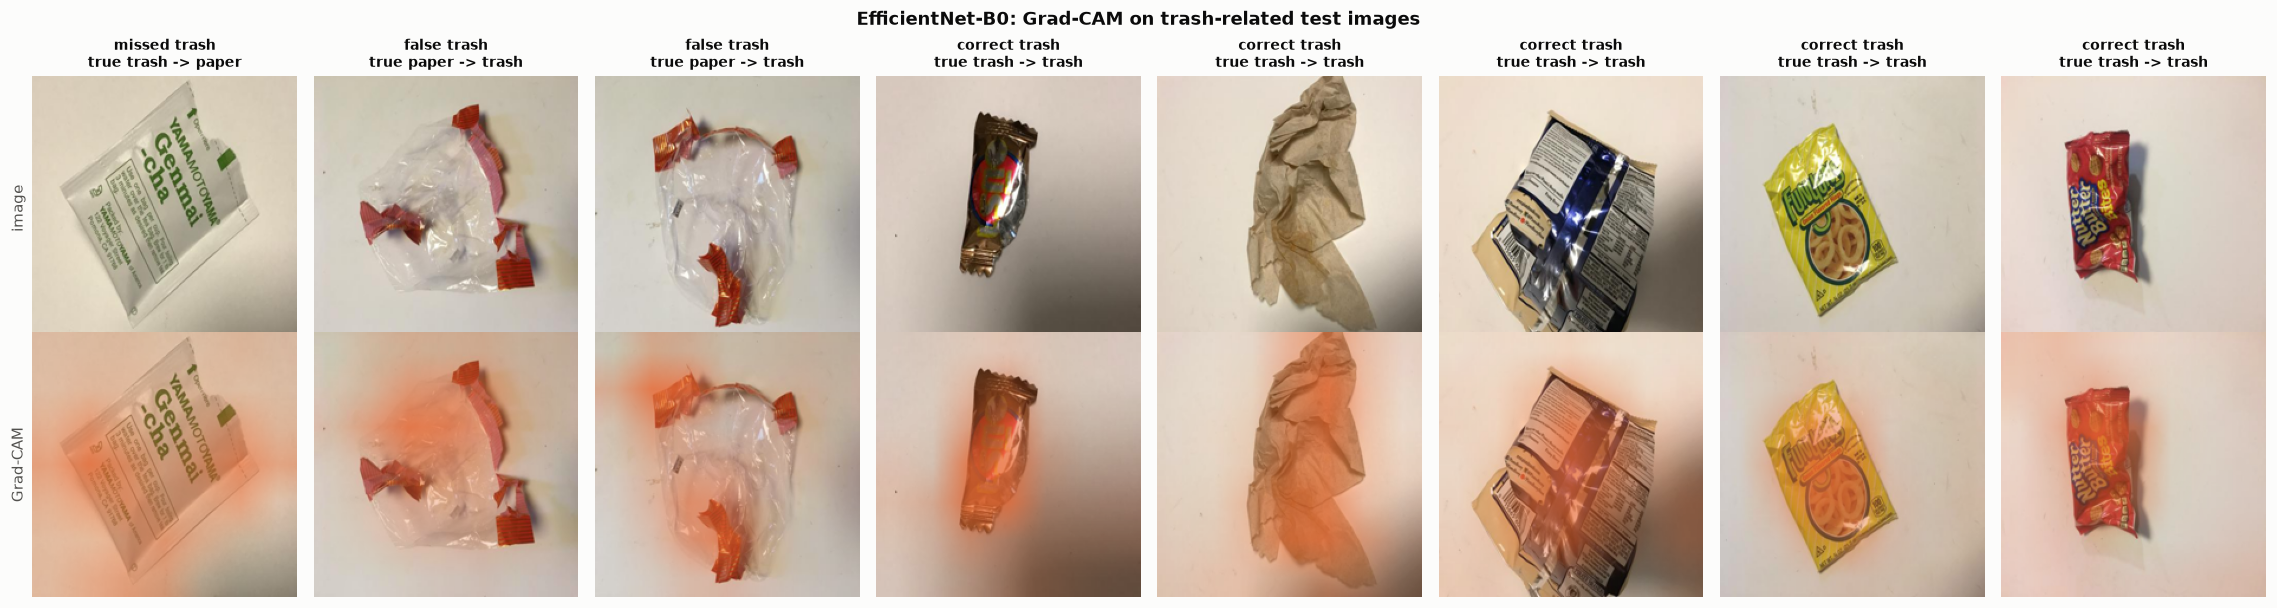

In [37]:
CAM_LAYER = {'WasteNet': lambda m: m.features[-1][1], 'ResNet-50': lambda m: m.layer4[-1],
             'EfficientNet-B0': lambda m: m.features[-1]}

def grad_cam(model, layer, x):
    """Grad-CAM heat map in [0, 1] for one normalised image x (3, H, W), for the predicted class."""
    store = {}
    def hook(m, inp, out):
        store['act'] = out
        out.register_hook(lambda g: store.__setitem__('grad', g))
    h = layer.register_forward_hook(hook)
    model.eval(); model.zero_grad(set_to_none=True)
    logits = model(x[None].to(DEVICE))
    h.remove()
    cls = int(logits.argmax(1))
    logits[0, cls].backward()
    weights = store['grad'].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * store['act']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[1:], mode='bilinear', align_corners=False)[0, 0]
    return ((cam - cam.min()) / (cam.max() - cam.min() + 1e-8)).detach().cpu().numpy(), cls

final_model = {'WasteNet': model_a, 'ResNet-50': model_b, 'EfficientNet-B0': model_c}[FINAL].to(DEVICE)
tp = np.where((y_test == TRASH) & (pred_test == TRASH))[0]
picks = [('missed trash', i) for i in fn[:4]] + [('false trash', i) for i in fp[:2]] + [('correct trash', i) for i in tp[:max(2, 8 - len(fn[:4]) - len(fp[:2]))]]
picks = picks[:8]

fig, axes = plt.subplots(2, len(picks), figsize=(2.6 * len(picks), 5.6), squeeze=False)
for col, (kind, i) in enumerate(picks):
    img = Image.open(test_df.path[i]).convert('RGB')
    cam, cls = grad_cam(final_model, CAM_LAYER[FINAL](final_model), eval_tf(img))
    shown = img.resize((IMG_SIZE, IMG_SIZE))
    axes[0, col].imshow(shown); axes[1, col].imshow(shown); axes[1, col].imshow(cam, cmap=CAM_CMAP, vmin=0, vmax=1)
    axes[0, col].set_title(f'{kind}\ntrue {CLASSES[y_test[i]]} -> {CLASSES[cls]}', fontsize=9)
    hide_axes(axes[0, col]); hide_axes(axes[1, col])
axes[0, 0].set_ylabel('image', fontsize=10); axes[1, 0].set_ylabel('Grad-CAM', fontsize=10)
fig.suptitle(f'{FINAL}: Grad-CAM on trash-related test images', fontsize=12, fontweight='bold')
plt.tight_layout(); save(fig, '20_gradcam_trash'); plt.show()

**Why the trash class fails (analysis)**

* The selected model finds **19 of 20 trash images (recall 0.95)** and raises **2 false trash alarms (precision 0.90)**. Only 3 of its 19 test errors involve trash.
* **Missed trash (1 image):** a printed tea sachet (`trash5.jpg`) predicted as *paper* (P = 0.59, P(trash) = 0.29). The sachet is made of paper-like laminate with printed text, so it *looks* like paper. It is "trash" because a multi-layer laminate is not recyclable, which a camera cannot see. In the t-SNE it lies **inside the paper cluster**. Its Grad-CAM is diffuse and spread over the background, i.e. the model found no strong evidence either way.
* **False trash (2 images):** `paper590.jpg` and `paper591.jpg` show a crumpled **clear plastic bag** labelled *paper* (label noise, see 10.4). Grad-CAM points at the transparent film and its edges, the same kind of crinkled-film cue the model uses for wrappers.
* **Correct trash:** Grad-CAM mostly highlights the item itself (candy wrapper, crisp packet, tissue). The model has learned the look of **crinkled, printed, flexible packaging**, not background shortcuts.
* **P(trash) histogram:** the two distributions barely overlap. True trash images mostly receive P(trash) > 0.85 and other classes mostly < 0.1; the few images in between include the three errors above.
* **t-SNE:** trash forms a small cluster **between paper and plastic**, i.e. next to the classes it is confused with. Pre-trained features separate it well, which also explains why the class weights had little effect.

**Root causes of trash errors:**

1. *Trash* is defined by **recyclability, not by material**. Many trash items are made of paper or plastic.
2. It is the **smallest and most varied class**: 96 training images of many unrelated objects.
3. There is **label noise** in neighbouring classes.
4. The test set has only **20 trash images**: one image moves trash recall by 5 points, and the trash-F1 95 % CI is 0.83–1.00.

Wrong predictions are also much less confident on average (0.59 vs. 0.87 for correct ones). A smart bin could therefore send low-confidence items to manual sorting instead of trusting every prediction.

## 12. Deployment view and inference
### 12.1 Model size and latency
A smart bin runs on a small embedded computer, so accuracy has to be weighed against model size and speed. Latency is measured for a single image (batch size 1, FP32): on the GPU, and on the CPU limited to 4 threads as a rough stand-in for an edge device.

In [38]:
@torch.no_grad()
def latency_ms(model, device, runs=30):
    m = copy.deepcopy(model).float().to(device).eval()
    x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=device)
    for _ in range(5):
        m(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(runs):
        m(x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / runs

threads = torch.get_num_threads()
torch.set_num_threads(4)
deploy = {}
for name, m in zip(MAIN_MODELS, (model_a, model_b, model_c)):
    deploy[name] = {'parameters (M)': RESULTS[name]['params'] / 1e6,
                    'weights file (MB)': (MODEL_DIR / f'{name}.pt').stat().st_size / 1e6,
                    'GPU latency (ms/img)': latency_ms(m, DEVICE) if DEVICE.type == 'cuda' else np.nan,
                    'CPU latency, 4 threads (ms/img)': latency_ms(m, torch.device('cpu')),
                    'training time (min)': RESULTS[name]['minutes'],
                    'test accuracy': metrics_table.loc[name, 'accuracy'],
                    'test macro-F1': metrics_table.loc[name, 'macro_f1'],
                    'test trash F1': metrics_table.loc[name, 'trash_f1']}
torch.set_num_threads(threads)
deploy_table = pd.DataFrame(deploy).T
display(deploy_table.round(3))
deploy_table.to_csv(RESULTS_DIR / 'deployment.csv')

,parameters (M),weights file (MB),GPU latency (ms/img),"CPU latency, 4 threads (ms/img)",training time (min),test accuracy,test macro-F1,test trash F1
WasteNet,3.389,13.591,1.485,38.910,5.797,0.817,0.799,0.632
ResNet-50,23.520,94.400,3.162,45.797,3.626,0.968,0.966,0.950
EfficientNet-B0,4.015,16.362,6.429,18.516,2.967,0.950,0.947,0.927


### 12.2 Classifying a single item
What a smart-bin controller would run: one photo in, a material class and confidence out. Low-confidence predictions can be routed to manual sorting instead of being trusted blindly.

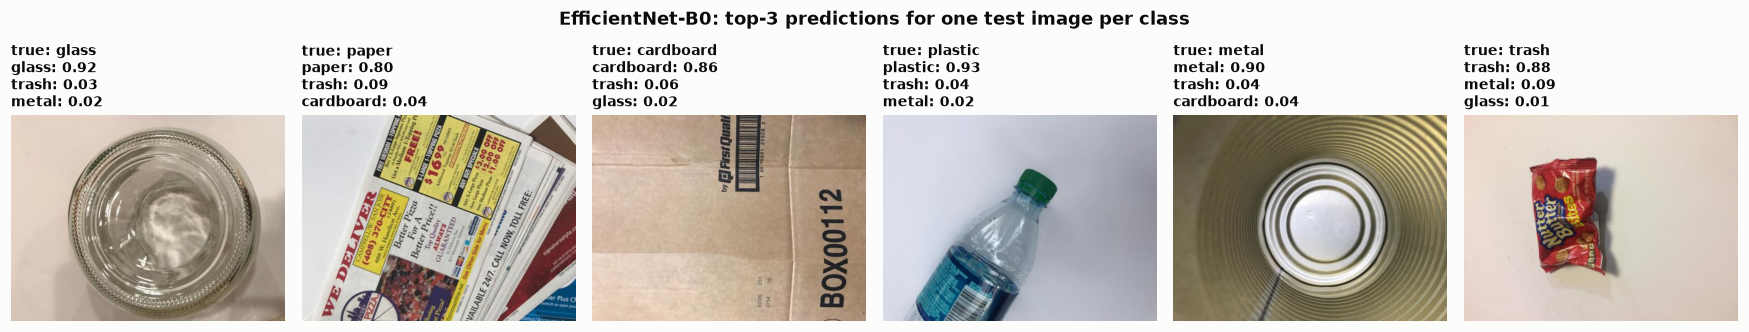

In [39]:
@torch.no_grad()
def classify(path, model, top_k=3):
    model.eval()
    x = eval_tf(Image.open(path).convert('RGB'))[None].to(DEVICE)
    prob = model(x).float().softmax(1)[0].cpu().numpy()
    order = prob.argsort()[::-1][:top_k]
    return [(CLASSES[i], float(prob[i])) for i in order]

demo = test_df.groupby('label').sample(1, random_state=SEED).set_index('label').loc[CLASSES]
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(16, 3.6))
for ax, (true, row) in zip(axes, demo.iterrows()):
    top = classify(row.path, final_model)
    ax.imshow(Image.open(row.path)); hide_axes(ax)
    ax.set_title(f'true: {true}\n' + '\n'.join(f'{c}: {p:.2f}' for c, p in top), fontsize=9, loc='left')
fig.suptitle(f'{FINAL}: top-3 predictions for one test image per class', fontsize=12, fontweight='bold')
plt.tight_layout(); save(fig, '21_inference_demo'); plt.show()

### 12.3 Print-size figures for the two-page report
The same results re-drawn at the printed width of an A4 page (17 cm, 8 pt text) so that axis labels and legends stay readable on paper.

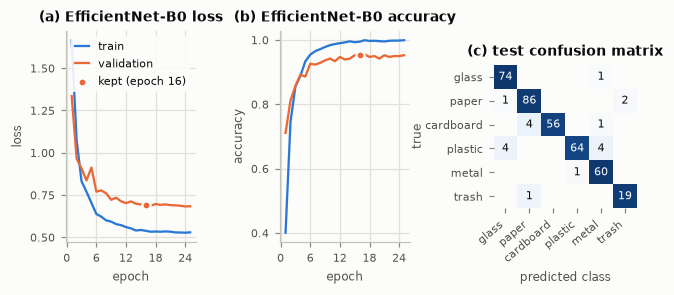

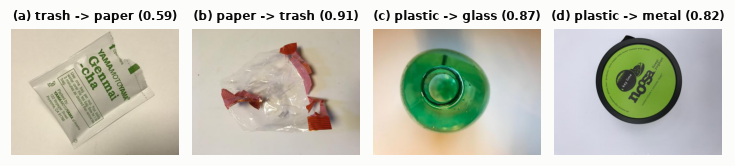

Fig. 2 files: ['trash5.jpg', 'paper590.jpg', 'plastic441.jpg', 'plastic307.jpg']


In [40]:
PRINT_RC = {'font.size': 8, 'axes.titlesize': 9, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
            'legend.fontsize': 7.5, 'lines.linewidth': 1.5, 'savefig.dpi': 300}
h = RESULTS[FINAL]['history']
b = h.val_f1.idxmax()
with plt.rc_context(PRINT_RC):
    fig = plt.figure(figsize=(6.7, 2.5))
    gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.1], wspace=0.62)
    for k, (key, label) in enumerate((('loss', 'loss'), ('acc', 'accuracy'))):
        ax = fig.add_subplot(gs[k])
        ax.plot(h.epoch, h[f'train_{key}'], color=SERIES[0], label='train')
        ax.plot(h.epoch, h[f'val_{key}'], color=SERIES[1], label='validation')
        ax.scatter(h.epoch[b], h[f'val_{key}'][b], s=28, color=SERIES[1], edgecolor=SURFACE, linewidth=1.5, zorder=3,
                   label=f'kept (epoch {h.epoch[b]})')
        ax.set(title=f'({"ab"[k]}) {FINAL} {label}', xlabel='epoch', ylabel=label)
        ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=5, integer=True))
        if key == 'loss':   # one legend serves both panels
            ax.legend(loc='best', handlelength=1.2, frameon=True, facecolor=SURFACE, edgecolor='none', framealpha=0.9)
    ax = fig.add_subplot(gs[2])
    plot_confusion(ax, y_test, pred_test, '(c) test confusion matrix', fontsize=7.5, show_share=False)
    ax.set_ylabel('true', labelpad=1)
    save(fig, 'report_fig1_curves_confusion'); plt.show()

# Fig. 2: trash errors first (the class the problem statement asks about), then the most frequent other confusions
report_picks = [int(i) for i in list(fn[:2]) + list(fp[:1])]
report_picks += [int(i) for i in picked if int(i) not in report_picks][:4 - len(report_picks)]
with plt.rc_context(PRINT_RC):
    fig, axes = plt.subplots(1, 4, figsize=(6.7, 1.95))
    for k, (ax, i) in enumerate(zip(axes, report_picks)):
        ax.imshow(Image.open(test_df.path[i])); hide_axes(ax)
        ax.set_title(f'({"abcd"[k]}) {CLASSES[y_test[i]]} -> {CLASSES[pred_test[i]]} ({p_test[i].max():.2f})', fontsize=8)
    plt.tight_layout(); save(fig, 'report_fig2_errors'); plt.show()
print('Fig. 2 files:', [Path(test_df.path[i]).name for i in report_picks])

In [41]:
summary = {
    'final_model': FINAL,
    'images_used': int(len(df)), 'removed_label_conflicts': int(before - len(df)),
    'split_sizes': {s: int((df.split == s).sum()) for s in ('train', 'val', 'test')},
    'test_metrics': {n: {k: round(float(v), 4) for k, v in metrics_table.loc[n].items()} for n in metrics_table.index},
    'confidence_intervals': ci_table.to_dict(orient='index'),
    'final_per_class': per_class.drop(columns='F1 95% CI').round(4).to_dict(orient='index'),
    'final_confusion_matrix': cm_final.tolist(),
    'deployment': deploy_table.round(4).to_dict(orient='index'),
}
(RESULTS_DIR / 'summary.json').write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ('final_model', 'images_used', 'split_sizes')}, indent=2))
print(f'\nFigures saved to {FIG_DIR.resolve()}, metrics to {RESULTS_DIR.resolve()}, weights to {MODEL_DIR.resolve()}')

{
  "final_model": "EfficientNet-B0",
  "images_used": 2521,
  "split_sizes": {
    "train": 1766,
    "val": 377,
    "test": 378
  }
}

Figures saved to /home/karthik/Desktop/CBL/figures, metrics to /home/karthik/Desktop/CBL/results, weights to /home/karthik/Desktop/CBL/models


### 12.4 Figures for the extended (4-page) report
*Added after the main run.* These cells reload the best weights saved during training (`models/*.pt`), re-score the test set, check that the predictions reproduce the results of Section 10, and redraw the key results at the printed width of an A4 page (17 cm, 7–9 pt text).

In [42]:
MAIN_MODELS = ['WasteNet', 'ResNet-50', 'EfficientNet-B0']
FINAL = json.loads((RESULTS_DIR / 'summary.json').read_text())['final_model']
saved_metrics = pd.read_csv(RESULTS_DIR / 'test_metrics.csv', index_col=0)
BUILDERS = {'WasteNet': WasteNet, 'ResNet-50': lambda: build_resnet50()[0], 'EfficientNet-B0': lambda: build_efficientnet_b0()[0]}

PRED, MODELS = {}, {}
for name in MAIN_MODELS:
    model = BUILDERS[name]()
    model.load_state_dict(torch.load(MODEL_DIR / f'{name}.pt', map_location=DEVICE))
    model = model.to(DEVICE, memory_format=torch.channels_last).eval()
    p, y, f = predict(model, test_loader, features=True)
    PRED[name], MODELS[name] = dict(p=p, y=y, pred=p.argmax(1), f=f), model
    print(f'{name:16s} reloaded: test accuracy {accuracy_score(y, p.argmax(1)):.4f}, macro-F1 {f1_score(y, p.argmax(1), average="macro"):.4f}'
          f'   (Section 10: {saved_metrics.loc[name, "accuracy"]:.4f}, {saved_metrics.loc[name, "macro_f1"]:.4f})')

PRINT_RC = {'font.size': 8, 'axes.titlesize': 8.5, 'axes.labelsize': 8, 'xtick.labelsize': 7.5, 'ytick.labelsize': 7.5,
            'legend.fontsize': 7.5, 'lines.linewidth': 1.4, 'savefig.dpi': 300}

WasteNet         reloaded: test accuracy 0.8175, macro-F1 0.7994   (Section 10: 0.8175, 0.7994)


ResNet-50        reloaded: test accuracy 0.9683, macro-F1 0.9657   (Section 10: 0.9683, 0.9657)


EfficientNet-B0  reloaded: test accuracy 0.9497, macro-F1 0.9466   (Section 10: 0.9497, 0.9466)


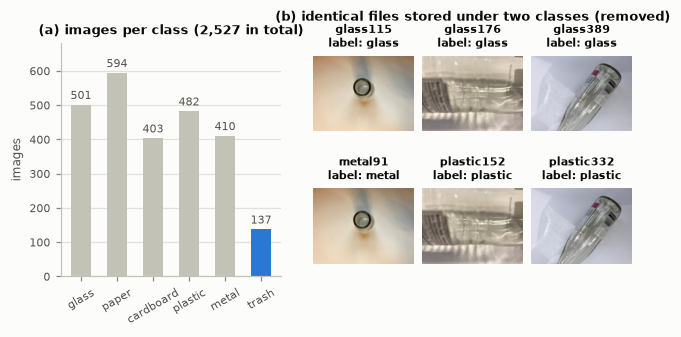

In [43]:
# Fig. A: class balance and the label conflicts found by the audit (Section 2)
with plt.rc_context(PRINT_RC):
    fig = plt.figure(figsize=(6.7, 2.75))
    outer = fig.add_gridspec(1, 2, width_ratios=[1, 1.45], wspace=0.12)
    ax = fig.add_subplot(outer[0])
    bars = ax.bar(CLASSES, counts.values, width=0.55, color=[SERIES[0] if c == 'trash' else AXIS for c in CLASSES])
    ax.bar_label(bars, padding=2, fontsize=7.5, color=INK_2)
    ax.set(ylabel='images', title='(a) images per class (2,527 in total)', ylim=(0, 680))
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='x', visible=False)
    inner = outer[1].subgridspec(2, len(pairs), hspace=0.32, wspace=0.08)
    for col, pair in enumerate(pairs):
        for row, (_, r) in enumerate(pair.iterrows()):
            a = fig.add_subplot(inner[row, col])
            a.imshow(Image.open(r.path)); hide_axes(a)
            a.set_title(f'{Path(r.path).stem}\nlabel: {r.label}', fontsize=7)
    pos = outer[1].get_position(fig)
    fig.text((pos.x0 + pos.x1) / 2, pos.y1 + 0.075, '(b) identical files stored under two classes (removed)',
             ha='center', fontsize=8.5, fontweight='bold')
    save(fig, 'print_fig_a_data'); plt.show()

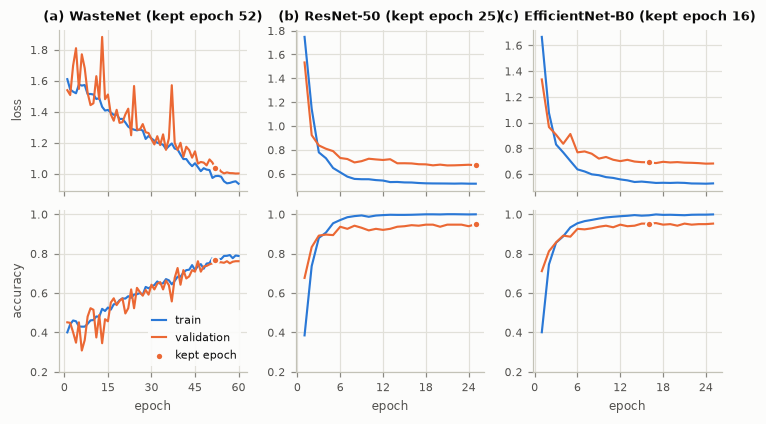

In [44]:
# Fig. B: learning curves of the three models (Sections 6-8)
with plt.rc_context(PRINT_RC):
    fig, axes = plt.subplots(2, 3, figsize=(6.7, 3.9), sharex='col')
    for col, name in enumerate(MAIN_MODELS):
        h = pd.read_csv(RESULTS_DIR / f'history_{name}.csv')
        b = h.val_f1.idxmax()
        for row, (key, label) in enumerate((('loss', 'loss'), ('acc', 'accuracy'))):
            ax = axes[row, col]
            ax.plot(h.epoch, h[f'train_{key}'], color=SERIES[0], label='train')
            ax.plot(h.epoch, h[f'val_{key}'], color=SERIES[1], label='validation')
            ax.scatter(h.epoch[b], h[f'val_{key}'][b], s=22, color=SERIES[1], edgecolor=SURFACE, linewidth=1.2,
                       zorder=3, label='kept epoch')
            ax.xaxis.set_major_locator(plt.MaxNLocator(nbins=5, integer=True))
            if col == 0:
                ax.set_ylabel(label)
            if row == 1:
                ax.set_xlabel('epoch'); ax.set_ylim(0.2, 1.02)
        axes[0, col].set_title(f'({"abc"[col]}) {name} (kept epoch {h.epoch[b]})')
    axes[1, 0].legend(loc='lower right', handlelength=1.2, frameon=True, facecolor=SURFACE, edgecolor='none', framealpha=0.9)
    fig.tight_layout(); save(fig, 'print_fig_b_learning_curves'); plt.show()

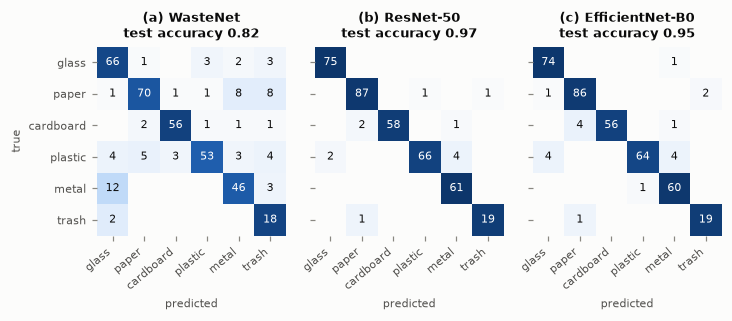

In [45]:
# Fig. C: test confusion matrices of the three models (Section 10)
with plt.rc_context(PRINT_RC):
    fig, axes = plt.subplots(1, 3, figsize=(6.7, 2.6))
    for k, (ax, name) in enumerate(zip(axes, MAIN_MODELS)):
        P = PRED[name]
        plot_confusion(ax, P['y'], P['pred'], f'({"abc"[k]}) {name}\ntest accuracy {accuracy_score(P["y"], P["pred"]):.2f}',
                       fontsize=7, show_share=False)
        ax.tick_params(labelsize=7)
        ax.set_xlabel('predicted', fontsize=7.5); ax.set_ylabel('true' if k == 0 else '', fontsize=7.5)
        if k:
            ax.set_yticklabels([])
    fig.tight_layout(); save(fig, 'print_fig_c_confusion'); plt.show()

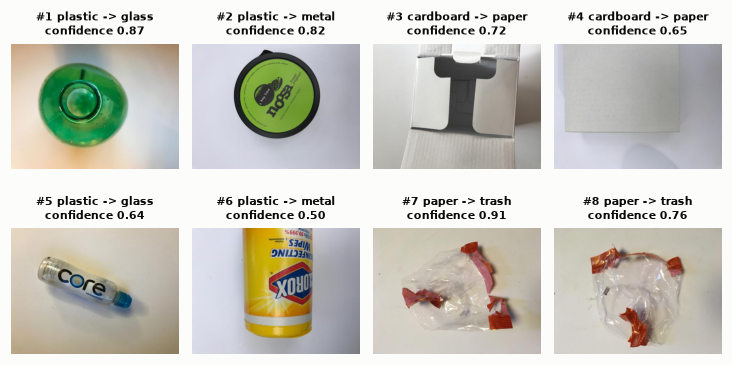

Fig. D files: ['plastic441.jpg', 'plastic307.jpg', 'cardboard294.jpg', 'cardboard296.jpg', 'plastic266.jpg', 'plastic356.jpg', 'paper590.jpg', 'paper591.jpg']


In [46]:
# Fig. D: misclassified test images of the selected model (same selection rule as Section 10.4)
P = PRED[FINAL]
err = np.where(P['pred'] != P['y'])[0]
pair_count = pd.Series(list(zip(P['y'][err], P['pred'][err]))).value_counts()
err = sorted(err, key=lambda i: (-pair_count[(P['y'][i], P['pred'][i])], -P['p'][i].max()))
picked8, per_pair = [], {}
for i in err:
    pair = (P['y'][i], P['pred'][i])
    if per_pair.get(pair, 0) < 2:
        picked8.append(i); per_pair[pair] = per_pair.get(pair, 0) + 1
    if len(picked8) == 8:
        break
with plt.rc_context(PRINT_RC):
    fig, axes = plt.subplots(2, 4, figsize=(6.7, 3.7))
    for k, (ax, i) in enumerate(zip(axes.flat, picked8), start=1):
        ax.imshow(Image.open(test_df.path[i])); hide_axes(ax)
        ax.set_title(f'#{k} {CLASSES[P["y"][i]]} -> {CLASSES[P["pred"][i]]}\nconfidence {P["p"][i].max():.2f}', fontsize=7.5)
    fig.tight_layout(); save(fig, 'print_fig_d_misclassified'); plt.show()
print('Fig. D files:', [Path(test_df.path[i]).name for i in picked8])

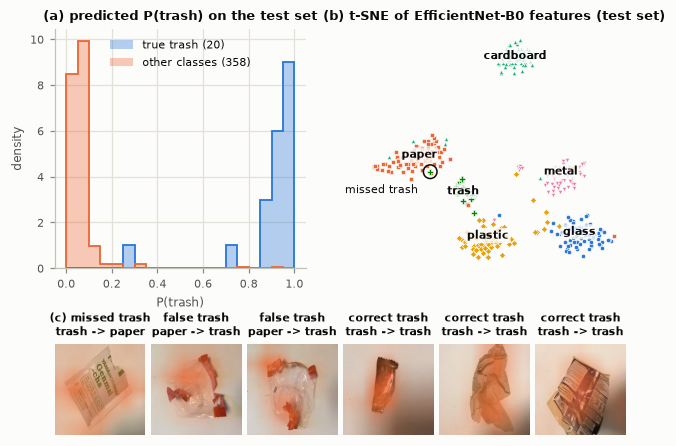

missed trash: ['trash5.jpg'] | false trash: ['paper590.jpg', 'paper591.jpg']


In [47]:
# Fig. E: trash-class analysis of the selected model (Section 11)
P = PRED[FINAL]
y, pred, p = P['y'], P['pred'], P['p']
fn_ = np.where((y == TRASH) & (pred != TRASH))[0]
fp_ = np.where((y != TRASH) & (pred == TRASH))[0]
tp_ = np.where((y == TRASH) & (pred == TRASH))[0]
emb = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(P['f'])
cams = ([('missed trash', i) for i in fn_] + [('false trash', i) for i in fp_] + [('correct trash', i) for i in tp_])[:6]

with plt.rc_context(PRINT_RC):
    fig = plt.figure(figsize=(6.7, 5.0))
    gs = fig.add_gridspec(2, 1, height_ratios=[2.75, 1.45], hspace=0.32)
    top = gs[0].subgridspec(1, 2, width_ratios=[1, 1.05], wspace=0.22)
    a1 = fig.add_subplot(top[0])
    bins = np.linspace(0, 1, 21)
    for k, (mask, lab) in enumerate(((y == TRASH, f'true trash ({(y == TRASH).sum()})'),
                                     (y != TRASH, f'other classes ({(y != TRASH).sum()})'))):
        a1.hist(p[mask, TRASH], bins=bins, color=SERIES[k], alpha=0.35, density=True, label=lab)
        a1.hist(p[mask, TRASH], bins=bins, color=SERIES[k], histtype='step', lw=1.2, density=True)
    a1.set(title='(a) predicted P(trash) on the test set', xlabel='P(trash)', ylabel='density')
    a1.legend(loc='upper center')
    a2 = fig.add_subplot(top[1])
    for i, c in enumerate(CLASSES):
        m = y == i
        a2.scatter(emb[m, 0], emb[m, 1], s=16 if c == 'trash' else 8, marker=CLASS_MARKER[c], color=CLASS_COLOR[c],
                   edgecolor=SURFACE, linewidth=0.4, zorder=3 if c == 'trash' else 2)
        cx, cy = np.median(emb[m], axis=0)
        a2.annotate(c, (cx, cy), fontsize=7.5, fontweight='bold', ha='center', color=INK, zorder=4,
                    bbox=dict(boxstyle='round,pad=0.15', fc=SURFACE, ec='none', alpha=0.8))
    a2.scatter(emb[fn_, 0], emb[fn_, 1], s=80, facecolor='none', edgecolor=INK, linewidth=1, zorder=4)
    for i in fn_:
        a2.annotate('missed trash', (emb[i, 0], emb[i, 1]), xytext=(-8, -14), textcoords='offset points', ha='right', fontsize=7,
                    color=INK, zorder=5, bbox=dict(boxstyle='round,pad=0.15', fc=SURFACE, ec='none', alpha=0.9))
    hide_axes(a2); a2.set_title(f'(b) t-SNE of {FINAL} features (test set)')
    bottom = gs[1].subgridspec(1, len(cams), wspace=0.06)
    model = MODELS[FINAL]
    for k, (kind, i) in enumerate(cams):
        img = Image.open(test_df.path[i]).convert('RGB')
        cam, cls = grad_cam(model, CAM_LAYER[FINAL](model), eval_tf(img))
        a = fig.add_subplot(bottom[k])
        a.imshow(img.resize((IMG_SIZE, IMG_SIZE))); a.imshow(cam, cmap=CAM_CMAP, vmin=0, vmax=1); hide_axes(a)
        a.set_title(f'{"(c) " if k == 0 else ""}{kind}\n{CLASSES[y[i]]} -> {CLASSES[cls]}', fontsize=7)
    save(fig, 'print_fig_e_trash'); plt.show()
print('missed trash:', [Path(test_df.path[i]).name for i in fn_], '| false trash:', [Path(test_df.path[i]).name for i in fp_])

## 13. Conclusions

* A fine-tuned **EfficientNet-B0** (selected on validation) classifies single waste items with **test accuracy 0.95 and macro-F1 0.95**. On the minority class it reaches **trash recall 0.95 and F1 0.93**, with only 4 M parameters and about 18 ms per image on 4 CPU threads.
* **Transfer learning is the key design decision:** a carefully designed CNN trained from scratch reaches only macro-F1 0.80 (trash F1 0.63) on 1.8 k training images.
* **Class imbalance** was handled with per-class reporting, macro-F1 model selection and a class-weighted loss. The ablation shows the weighting does **not** measurably change the pre-trained model; for the scratch CNN it increases trash recall at the cost of precision.
* **Data quality matters as much as the model:** the audit found 3 label-conflicting duplicates, and 2 of the remaining test errors are themselves mislabelled images.
* Remaining errors are **material look-alikes** (clear or green plastic vs. glass, plastic lids vs. metal, white paperboard vs. paper).
* **Next steps:** fine-tune on photos from a real bin (clutter, several items, dirt), add a confidence-based reject option, ensemble ResNet-50 + EfficientNet-B0, and quantise EfficientNet-B0 for an embedded controller.

**Where to find what (Part F viva questions)**

| Question | Notebook section |
|---|---|
| Architecture and input size | 6 (WasteNet design), 7–8 (transfer learning), 4.1 (224 × 224 input) |
| Split and leakage prevention | 2.3 (duplicate audit), 3 (group-aware stratified split) |
| Why macro-F1 rather than accuracy | 5, 10.1 |
| Most confused classes and why | 10.2 (confusion matrices), 10.4 (misclassified images) |
| Over- or under-fitting | 6–8 learning curves, *Observations (training)* |
| Specific challenge (trash imbalance) | 4.2, 9, 10.3, 11 |
| Real-world deployment | 12 |
| Reproducibility (seed, split, versions) | 1.1–1.2 (versions, seed, deterministic cuDNN), `results/split.csv` |

## References
1. G. Thung and M. Yang, "Classification of Trash for Recyclability Status," CS229 project report, Stanford University, 2016. Dataset: https://github.com/garythung/trashnet
2. K. He, X. Zhang, S. Ren and J. Sun, "Deep Residual Learning for Image Recognition," CVPR 2016.
3. M. Tan and Q. V. Le, "EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks," ICML 2019.
4. R. R. Selvaraju et al., "Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization," ICCV 2017.
5. L. van der Maaten and G. Hinton, "Visualizing Data using t-SNE," JMLR 9, 2008.
6. L. N. Smith and N. Topin, "Super-Convergence: Very Fast Training of Neural Networks Using Large Learning Rates" (one-cycle schedule), 2019.
7. Pre-trained ImageNet weights and model definitions: torchvision (PyTorch).